In [33]:
from pathlib import Path
import pandas as pd

metrics_parent_dir = Path(
    "/compute/oven-0-13/jwinchel/spatial_adata/metrics_eval_syndri_grid/"
)


def concatenate_metric_files(parent_dir, filename):
    files = sorted(parent_dir.rglob(filename))

    if not files:
        return pd.DataFrame()

    dfs = []
    for file in files:
        df = pd.read_csv(file)

        # Optional provenance columns
        df["source_file"] = str(file)
        df["source_dir"] = file.parent.name

        dfs.append(df)

    return pd.concat(dfs, axis=0, ignore_index=True)


sep_df = concatenate_metric_files(
    metrics_parent_dir,
    "cell_type_separation_metrics_worstadj.csv"
)

tcell_df = concatenate_metric_files(
    metrics_parent_dir,
    "tcell_contamination_metrics_worstadj.csv"
)

teff_df = concatenate_metric_files(
    metrics_parent_dir,
    "tcell_contamination_effects_worstadj.csv"
)

top_gene_profiles = concatenate_metric_files(
    metrics_parent_dir,
    "tissue_cell_type_profiles_worstadj.csv"
)

print(f"Separation metrics: {len(sep_df):,} rows")
print(f"T-cell contamination metrics: {len(tcell_df):,} rows")
print(f"T-cell contamination effects: {len(teff_df):,} rows")
print(f"Tissue/cell-type profiles: {len(top_gene_profiles):,} rows")

Separation metrics: 532 rows
T-cell contamination metrics: 72,340 rows
T-cell contamination effects: 12,044 rows
Tissue/cell-type profiles: 0 rows


In [ ]:
tcell_df['top_n'].unique()

array([nan, 20.])

In [34]:
sep_df.source_file.unique()

array(['/compute/oven-0-13/jwinchel/spatial_adata/metrics_eval_syndri_grid/celltype_specific_nonlinear_power/GSM9509156_breast_breast_B17_B17_rctd_annotated_val_worstadj_med_with_admix_probs/cell_type_separation_metrics_worstadj.csv',
       '/compute/oven-0-13/jwinchel/spatial_adata/metrics_eval_syndri_grid/celltype_specific_nonlinear_power/GSM9509157_breast_breast_B16_B16_rctd_annotated_val_worstadj_med_with_admix_probs/cell_type_separation_metrics_worstadj.csv',
       '/compute/oven-0-13/jwinchel/spatial_adata/metrics_eval_syndri_grid/celltype_specific_nonlinear_power/GSM9509158_breast_breast_B15_B15_rctd_annotated_val_worstadj_med_with_admix_probs/cell_type_separation_metrics_worstadj.csv',
       '/compute/oven-0-13/jwinchel/spatial_adata/metrics_eval_syndri_grid/celltype_specific_nonlinear_power/GSM9509159_breast_breast_B14_B14_rctd_annotated_val_worstadj_med_with_admix_probs/cell_type_separation_metrics_worstadj.csv',
       '/compute/oven-0-13/jwinchel/spatial_adata/metrics_ev

In [ ]:
import anndata as ad
st_data = ad.read_h5ad(sep_df['source_file'].iloc[0])
st_data

OSError: Unable to synchronously open file (file signature not found)

In [ ]:
sc_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/split_sc_ref/breast_cancer_chromium_genesubset.h5ad')

In [ ]:
sc_data.obs['Level2'].unique()

['T_NK', 'B', 'Tu_B1', 'Vessel', 'Fibro_muscle', 'Myeloid', 'Mast_cell', 'Tu_B3', 'Tu_B4']
Categories (9, object): ['B', 'Fibro_muscle', 'Mast_cell', 'Myeloid', ..., 'Tu_B1', 'Tu_B3', 'Tu_B4', 'Vessel']

In [ ]:
sc_data.obs

,orig.ident,nCount_RNA,nFeature_RNA,sample_id,percent_mt,percent_ribo,percent_hb,nCount_SCT,nFeature_SCT,SCT_snn_res.0.8,...,block_age_months,is_primary_data,cell_type,assay,disease,sex,tissue,self_reported_ethnicity,development_stage,observation_joinid
B1_AAACAAGCAGCCTTCAACTTTAGG-1,SeuratProject,530.410469,482,6,1.156690,0.0,0.0,670.0,481,1,...,56,True,natural T-regulatory cell,10x gene expression flex,invasive lobular breast carcinoma,female,parenchyma of mammary gland,unknown,adult stage,=d8=l`C_r-
B1_AAACAAGCAGGAATAAACTTTAGG-1,SeuratProject,742.410952,283,6,0.851523,0.0,0.0,880.0,282,22,...,56,True,plasma cell,10x gene expression flex,invasive lobular breast carcinoma,female,parenchyma of mammary gland,unknown,adult stage,uC9A8agc8E
B1_AAACAAGCATTTGGAGACTTTAGG-1,SeuratProject,724.332693,612,6,1.238582,0.0,0.0,792.0,612,6,...,56,True,cytotoxic T cell,10x gene expression flex,invasive lobular breast carcinoma,female,parenchyma of mammary gland,unknown,adult stage,w;D?AlM@1l
B1_AAACCAATCACGTTCAACTTTAGG-1,SeuratProject,2619.023516,1360,6,8.685321,0.0,0.0,1778.0,1246,17,...,56,True,malignant cell,10x gene expression flex,invasive lobular breast carcinoma,female,parenchyma of mammary gland,unknown,adult stage,g8+SfmziP<
B1_AAACCAATCGTCAATTACTTTAGG-1,SeuratProject,1676.895730,758,6,0.644417,0.0,0.0,1420.0,749,22,...,56,True,plasma cell,10x gene expression flex,invasive lobular breast carcinoma,female,parenchyma of mammary gland,unknown,adult stage,=zZ<7&u>Us
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
B4_rep_TTTGCGCAGTGAATCAATGTTGAC-1,SeuratProject,729.703258,554,9,0.000000,0.0,0.0,830.0,552,8,...,66,True,smooth muscle cell,10x gene expression flex,invasive ductal breast carcinoma,female,parenchyma of mammary gland,unknown,adult stage,S-^tSV2sSc
B4_rep_TTTGCTCTCCATCCTTATGTTGAC-1,SeuratProject,483.034144,428,9,0.000000,0.0,0.0,672.0,428,27,...,66,True,pericyte,10x gene expression flex,invasive ductal breast carcinoma,female,parenchyma of mammary gland,unknown,adult stage,J);s_@1Zmr
B4_rep_TTTGCTGAGATAGCCGATGTTGAC-1,SeuratProject,596.539340,506,9,0.125133,0.0,0.0,707.0,505,8,...,66,True,smooth muscle cell,10x gene expression flex,invasive ductal breast carcinoma,female,parenchyma of mammary gland,unknown,adult stage,(Z@;%eSEk<
B4_rep_TTTGGACGTTGGTTACATGTTGAC-1,SeuratProject,4431.512697,2586,9,0.294368,0.0,0.0,1273.0,806,16,...,66,True,malignant cell,10x gene expression flex,invasive ductal breast carcinoma,female,parenchyma of mammary gland,unknown,adult stage,ks3mRcAM_l


In [35]:
sep_df['eval_config'] = sep_df['source_file'].apply(lambda x: x.split('/')[6])
sep_df

,tissue,source_file,case,cleaning_mode,cell_type_specific_removal,probability_transform,probability_removal_scale,group_admix_prob_thresholds,group_probability_removal_scales,group_achieved_removed_fractions,...,n_genes,n_labels,silhouette_score,calinski_harabasz,davies_bouldin,leiden_nmi_vs_label,leiden_adjusted_rand_vs_label,error,source_dir,eval_config
0,GSM9509156_breast_breast_B17_B17_rctd_annotate...,/compute/oven-0-13/jwinchel/spatial_adata/metr...,admixed,NaN,False,NaN,NaN,NaN,NaN,NaN,...,277.0,14.0,-0.012700,618.305770,10.329255,0.309045,0.203347,NaN,GSM9509156_breast_breast_B17_B17_rctd_annotate...,celltype_specific_nonlinear_power
1,GSM9509156_breast_breast_B17_B17_rctd_annotate...,/compute/oven-0-13/jwinchel/spatial_adata/metr...,cleaned_admixed_removed_frac_0.01,probability_scale,True,power,NaN,"{""CD4-positive, alpha-beta memory T cell"": nul...","{""CD4-positive, alpha-beta memory T cell"": 0.0...","{""CD4-positive, alpha-beta memory T cell"": 0.0...",...,277.0,14.0,-0.012635,620.715375,10.324156,0.301915,0.171962,NaN,GSM9509156_breast_breast_B17_B17_rctd_annotate...,celltype_specific_nonlinear_power
2,GSM9509156_breast_breast_B17_B17_rctd_annotate...,/compute/oven-0-13/jwinchel/spatial_adata/metr...,cleaned_admixed_removed_frac_0.02,probability_scale,True,power,NaN,"{""CD4-positive, alpha-beta memory T cell"": nul...","{""CD4-positive, alpha-beta memory T cell"": 0.1...","{""CD4-positive, alpha-beta memory T cell"": 0.0...",...,277.0,14.0,-0.012545,623.346405,10.310840,0.305894,0.203459,NaN,GSM9509156_breast_breast_B17_B17_rctd_annotate...,celltype_specific_nonlinear_power
3,GSM9509156_breast_breast_B17_B17_rctd_annotate...,/compute/oven-0-13/jwinchel/spatial_adata/metr...,cleaned_admixed_removed_frac_0.05,probability_scale,True,power,NaN,"{""CD4-positive, alpha-beta memory T cell"": nul...","{""CD4-positive, alpha-beta memory T cell"": 0.4...","{""CD4-positive, alpha-beta memory T cell"": 0.0...",...,277.0,14.0,-0.012092,633.365164,10.253179,0.294626,0.184775,NaN,GSM9509156_breast_breast_B17_B17_rctd_annotate...,celltype_specific_nonlinear_power
4,GSM9509156_breast_breast_B17_B17_rctd_annotate...,/compute/oven-0-13/jwinchel/spatial_adata/metr...,cleaned_admixed_removed_frac_0.1,probability_scale,True,power,NaN,"{""CD4-positive, alpha-beta memory T cell"": nul...","{""CD4-positive, alpha-beta memory T cell"": 0.8...","{""CD4-positive, alpha-beta memory T cell"": 0.1...",...,277.0,14.0,-0.010516,661.472674,10.458510,0.296379,0.195070,NaN,GSM9509156_breast_breast_B17_B17_rctd_annotate...,celltype_specific_nonlinear_power
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
527,GSM9509174_breast_breast_B1_B1_3_rctd_annotate...,/compute/oven-0-13/jwinchel/spatial_adata/metr...,cleaned_admixed_removed_frac_0.02,zero,False,NaN,NaN,NaN,NaN,NaN,...,277.0,14.0,0.034866,1804.887161,7.281802,0.463167,0.338242,NaN,GSM9509174_breast_breast_B1_B1_3_rctd_annotate...,global_zero
528,GSM9509174_breast_breast_B1_B1_3_rctd_annotate...,/compute/oven-0-13/jwinchel/spatial_adata/metr...,cleaned_admixed_removed_frac_0.05,zero,False,NaN,NaN,NaN,NaN,NaN,...,277.0,14.0,0.033666,1838.621850,7.299246,0.463215,0.321905,NaN,GSM9509174_breast_breast_B1_B1_3_rctd_annotate...,global_zero
529,GSM9509174_breast_breast_B1_B1_3_rctd_annotate...,/compute/oven-0-13/jwinchel/spatial_adata/metr...,cleaned_admixed_removed_frac_0.1,zero,False,NaN,NaN,NaN,NaN,NaN,...,277.0,14.0,0.030350,1861.635997,7.310527,0.449756,0.322968,NaN,GSM9509174_breast_breast_B1_B1_3_rctd_annotate...,global_zero
530,GSM9509174_breast_breast_B1_B1_3_rctd_annotate...,/compute/oven-0-13/jwinchel/spatial_adata/metr...,cleaned_admixed_removed_frac_0.2,zero,False,NaN,NaN,NaN,NaN,NaN,...,277.0,14.0,0.025038,1894.488187,7.405452,0.433353,0.319661,NaN,GSM9509174_breast_breast_B1_B1_3_rctd_annotate...,global_zero


In [44]:
sep_df['tissue'].unique()

array(['GSM9509156_breast_breast_B17_B17_rctd_annotated_val_worstadj',
       'GSM9509157_breast_breast_B16_B16_rctd_annotated_val_worstadj',
       'GSM9509158_breast_breast_B15_B15_rctd_annotated_val_worstadj',
       'GSM9509159_breast_breast_B14_B14_rctd_annotated_val_worstadj',
       'GSM9509160_breast_breast_B2_B2_rctd_annotated_val_worstadj',
       'GSM9509161_breast_breast_B13_B13_rctd_annotated_val_worstadj',
       'GSM9509162_breast_breast_B12_B12_rctd_annotated_val_worstadj',
       'GSM9509163_breast_breast_B11_B11_rctd_annotated_val_worstadj',
       'GSM9509164_breast_breast_B10_B10_rctd_annotated_val_worstadj',
       'GSM9509165_breast_breast_B4_B4_rctd_annotated_val_worstadj',
       'GSM9509166_breast_breast_B9_B9_rctd_annotated_val_worstadj',
       'GSM9509167_breast_breast_B8_B8_rctd_annotated_val_worstadj',
       'GSM9509168_breast_breast_B7_B7_rctd_annotated_val_worstadj',
       'GSM9509169_breast_breast_B6_B6_rctd_annotated_val_worstadj',
       'GSM9509170

                                              tissue  \
0  GSM9509156_breast_breast_B17_B17_rctd_annotate...   
4  GSM9509156_breast_breast_B17_B17_rctd_annotate...   
5  GSM9509156_breast_breast_B17_B17_rctd_annotate...   
6  GSM9509156_breast_breast_B17_B17_rctd_annotate...   
7  GSM9509157_breast_breast_B16_B16_rctd_annotate...   

                                         source_file  \
0  /compute/oven-0-13/jwinchel/spatial_adata/metr...   
4  /compute/oven-0-13/jwinchel/spatial_adata/metr...   
5  /compute/oven-0-13/jwinchel/spatial_adata/metr...   
6  /compute/oven-0-13/jwinchel/spatial_adata/metr...   
7  /compute/oven-0-13/jwinchel/spatial_adata/metr...   

                               case      cleaning_mode  \
0                           admixed                NaN   
4  cleaned_admixed_removed_frac_0.1  probability_scale   
5  cleaned_admixed_removed_frac_0.2  probability_scale   
6                             SPLIT                NaN   
7                           admixed 

/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hu

GSM9509156_breast_breast_B17_B17_rctd_annotated_val_worstadj
GSM9509157_breast_breast_B16_B16_rctd_annotated_val_worstadj
GSM9509158_breast_breast_B15_B15_rctd_annotated_val_worstadj
GSM9509159_breast_breast_B14_B14_rctd_annotated_val_worstadj
GSM9509160_breast_breast_B2_B2_rctd_annotated_val_worstadj
GSM9509161_breast_breast_B13_B13_rctd_annotated_val_worstadj
GSM9509162_breast_breast_B12_B12_rctd_annotated_val_worstadj
GSM9509163_breast_breast_B11_B11_rctd_annotated_val_worstadj
GSM9509164_breast_breast_B10_B10_rctd_annotated_val_worstadj
GSM9509165_breast_breast_B4_B4_rctd_annotated_val_worstadj
GSM9509166_breast_breast_B9_B9_rctd_annotated_val_worstadj
GSM9509167_breast_breast_B8_B8_rctd_annotated_val_worstadj
GSM9509168_breast_breast_B7_B7_rctd_annotated_val_worstadj
GSM9509169_breast_breast_B6_B6_rctd_annotated_val_worstadj
GSM9509170_breast_breast_B3_B3_rctd_annotated_val_worstadj
GSM9509171_breast_breast_B5_B5_rctd_annotated_val_worstadj
GSM9509172_breast_breast_B1_B1_1_rctd_an

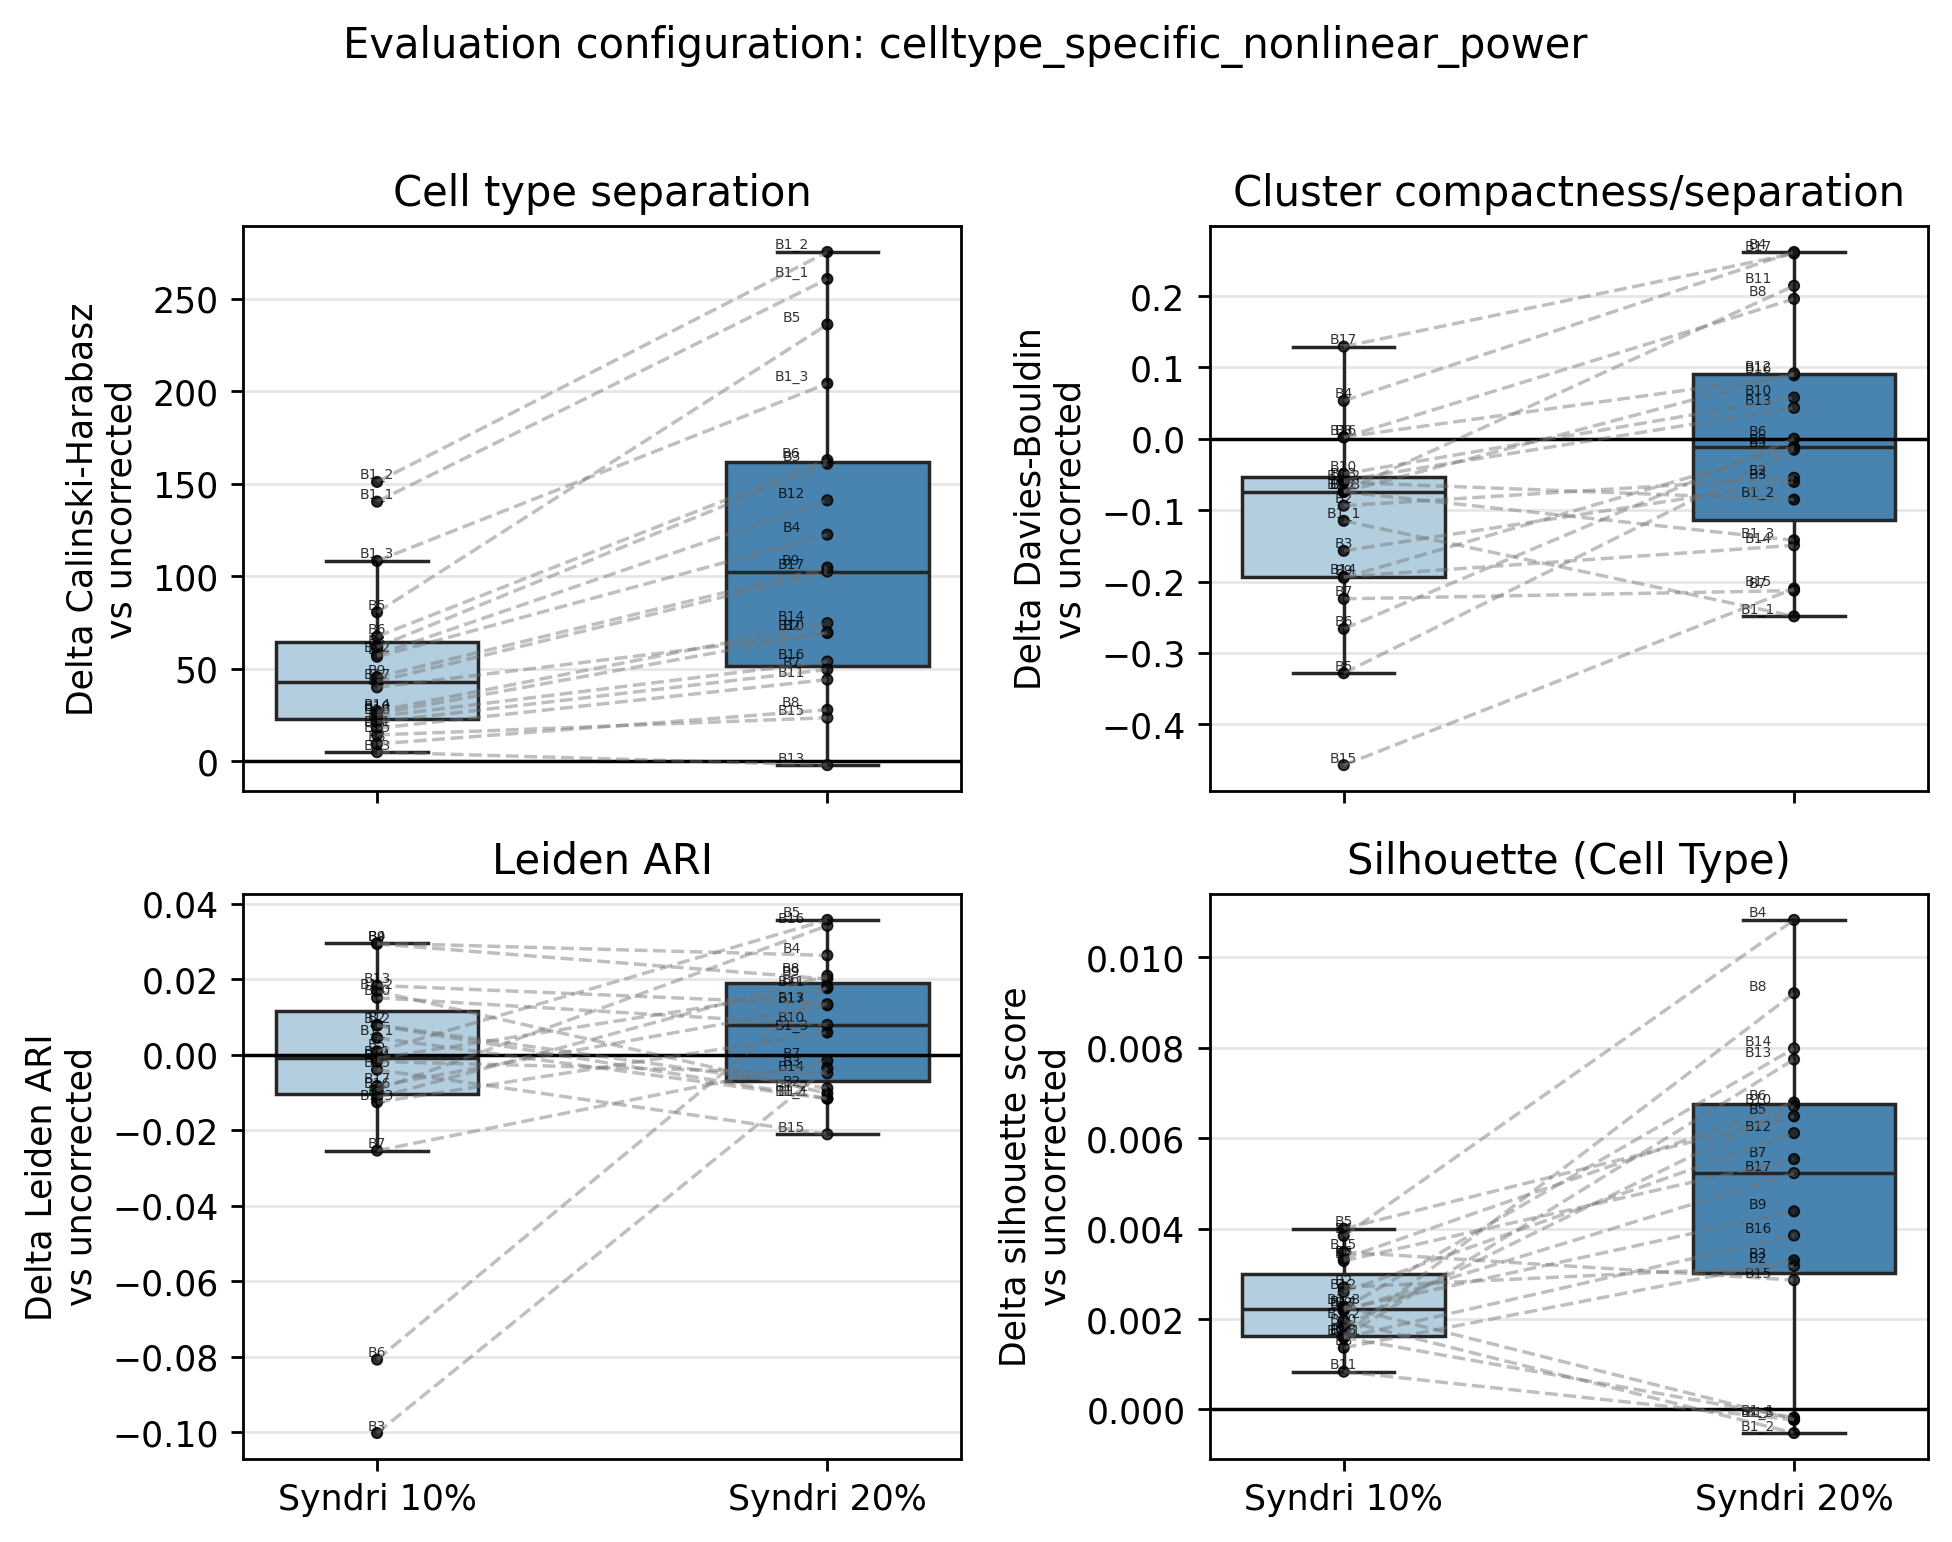

/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


GSM9509156_breast_breast_B17_B17_rctd_annotated_val_worstadj
GSM9509157_breast_breast_B16_B16_rctd_annotated_val_worstadj
GSM9509158_breast_breast_B15_B15_rctd_annotated_val_worstadj
GSM9509159_breast_breast_B14_B14_rctd_annotated_val_worstadj
GSM9509160_breast_breast_B2_B2_rctd_annotated_val_worstadj
GSM9509161_breast_breast_B13_B13_rctd_annotated_val_worstadj
GSM9509162_breast_breast_B12_B12_rctd_annotated_val_worstadj
GSM9509163_breast_breast_B11_B11_rctd_annotated_val_worstadj
GSM9509164_breast_breast_B10_B10_rctd_annotated_val_worstadj
GSM9509165_breast_breast_B4_B4_rctd_annotated_val_worstadj
GSM9509166_breast_breast_B9_B9_rctd_annotated_val_worstadj
GSM9509167_breast_breast_B8_B8_rctd_annotated_val_worstadj
GSM9509168_breast_breast_B7_B7_rctd_annotated_val_worstadj
GSM9509169_breast_breast_B6_B6_rctd_annotated_val_worstadj
GSM9509170_breast_breast_B3_B3_rctd_annotated_val_worstadj
GSM9509171_breast_breast_B5_B5_rctd_annotated_val_worstadj
GSM9509172_breast_breast_B1_B1_1_rctd_an

/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


GSM9509156_breast_breast_B17_B17_rctd_annotated_val_worstadj
GSM9509157_breast_breast_B16_B16_rctd_annotated_val_worstadj
GSM9509158_breast_breast_B15_B15_rctd_annotated_val_worstadj
GSM9509159_breast_breast_B14_B14_rctd_annotated_val_worstadj
GSM9509160_breast_breast_B2_B2_rctd_annotated_val_worstadj
GSM9509161_breast_breast_B13_B13_rctd_annotated_val_worstadj
GSM9509162_breast_breast_B12_B12_rctd_annotated_val_worstadj
GSM9509163_breast_breast_B11_B11_rctd_annotated_val_worstadj
GSM9509164_breast_breast_B10_B10_rctd_annotated_val_worstadj
GSM9509165_breast_breast_B4_B4_rctd_annotated_val_worstadj
GSM9509166_breast_breast_B9_B9_rctd_annotated_val_worstadj
GSM9509167_breast_breast_B8_B8_rctd_annotated_val_worstadj
GSM9509168_breast_breast_B7_B7_rctd_annotated_val_worstadj
GSM9509169_breast_breast_B6_B6_rctd_annotated_val_worstadj
GSM9509170_breast_breast_B3_B3_rctd_annotated_val_worstadj
GSM9509171_breast_breast_B5_B5_rctd_annotated_val_worstadj
GSM9509172_breast_breast_B1_B1_1_rctd_an

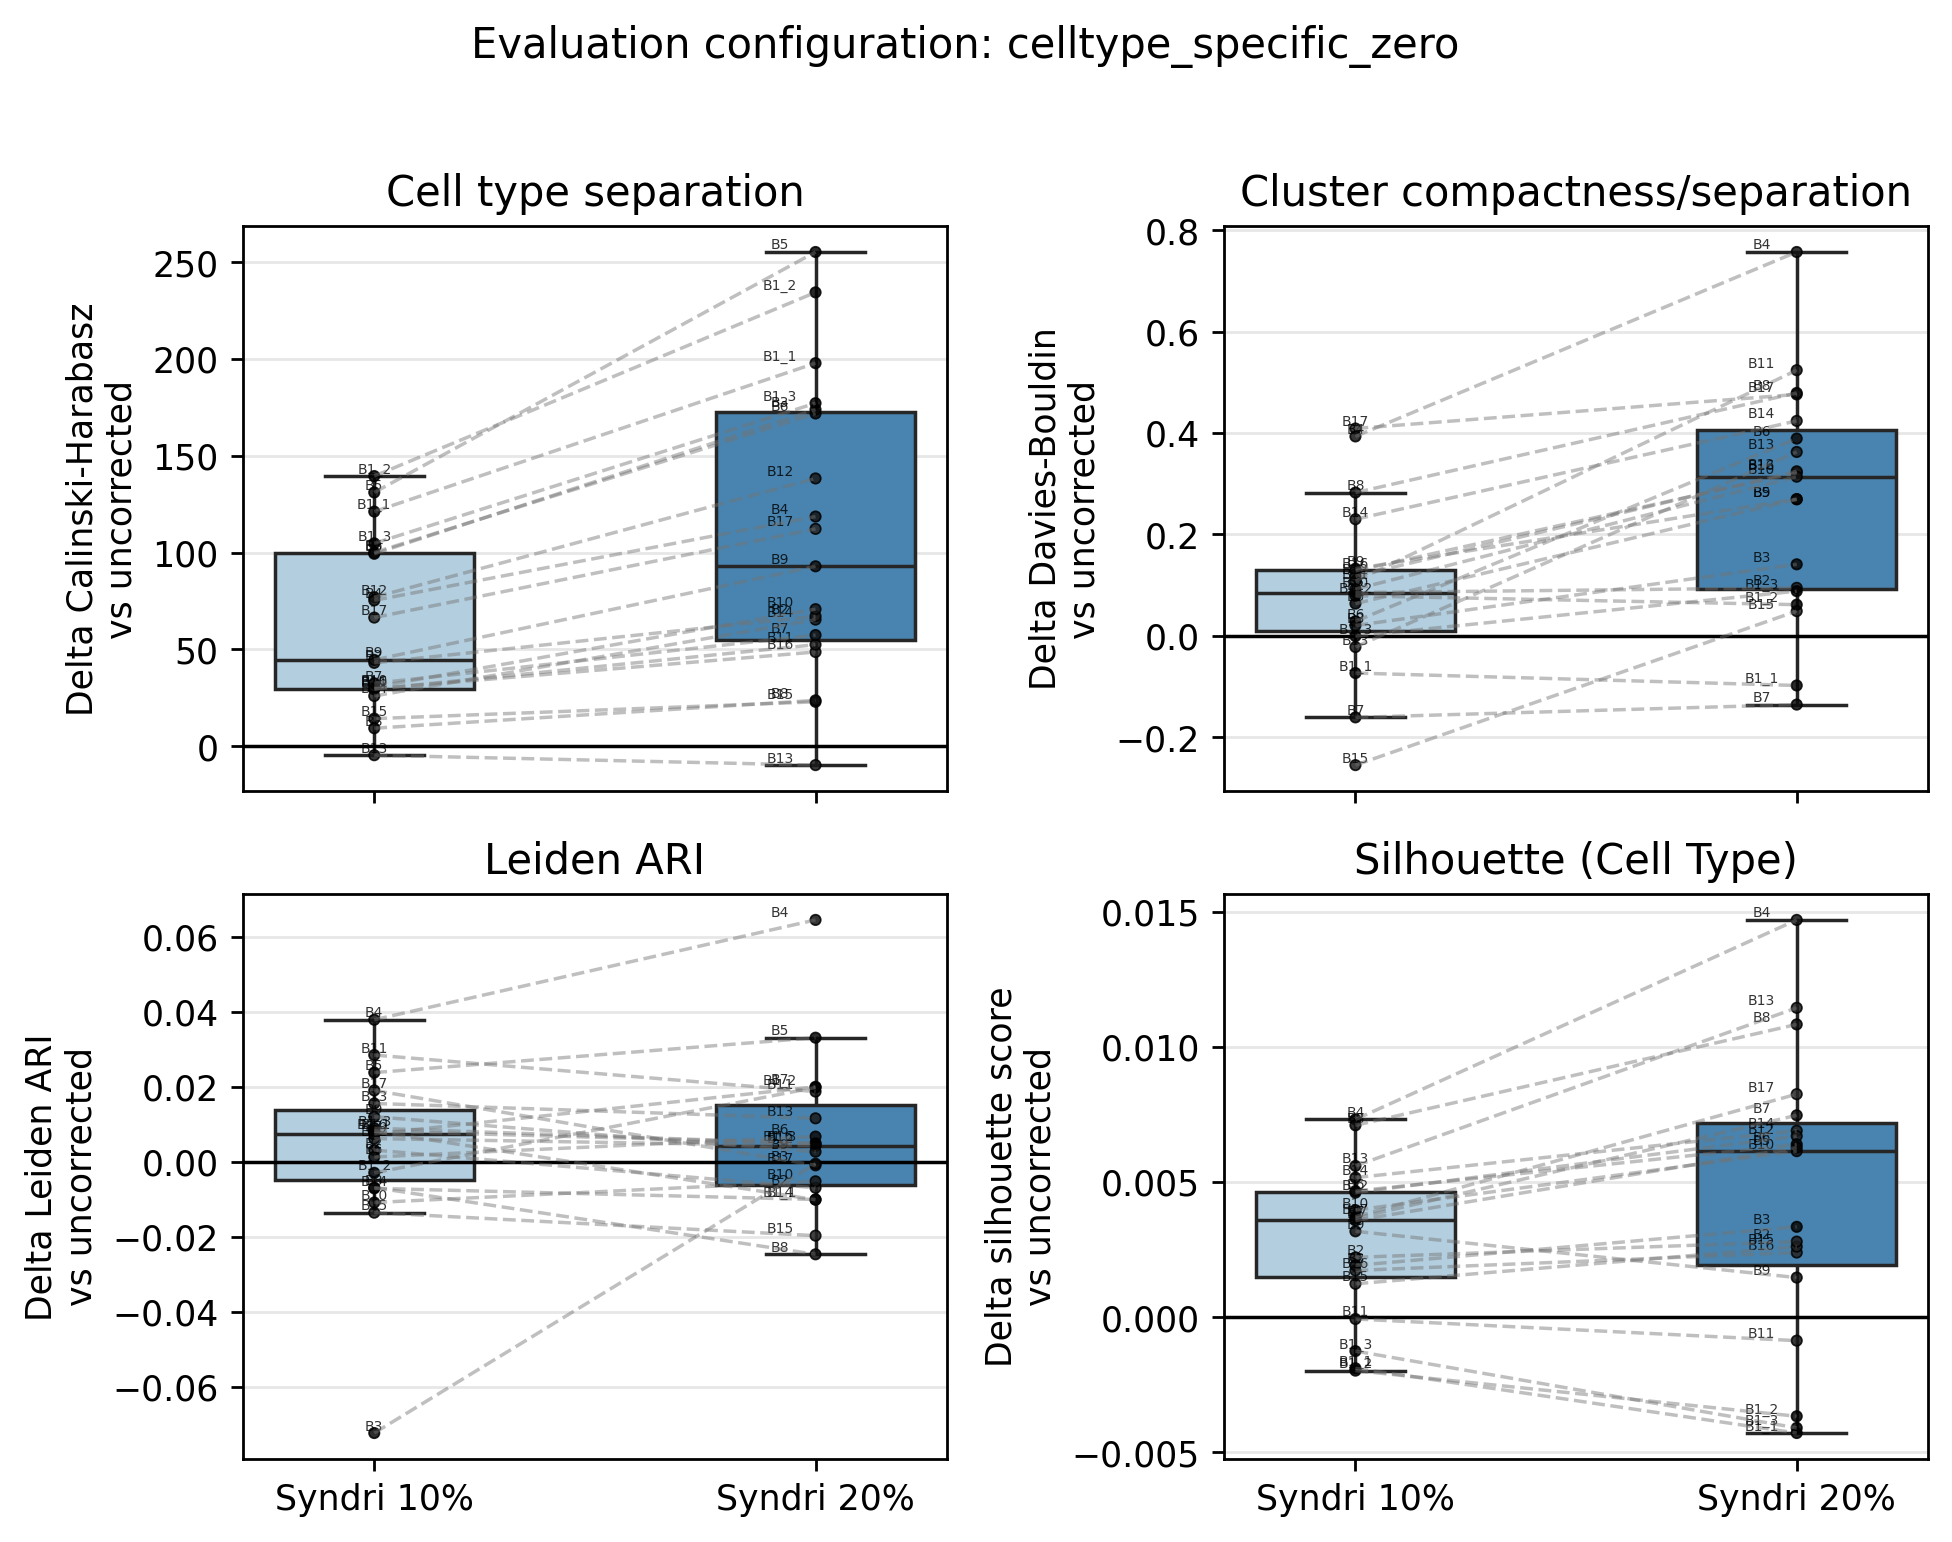

/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hu

GSM9509156_breast_breast_B17_B17_rctd_annotated_val_worstadj
GSM9509157_breast_breast_B16_B16_rctd_annotated_val_worstadj
GSM9509158_breast_breast_B15_B15_rctd_annotated_val_worstadj
GSM9509159_breast_breast_B14_B14_rctd_annotated_val_worstadj
GSM9509160_breast_breast_B2_B2_rctd_annotated_val_worstadj
GSM9509161_breast_breast_B13_B13_rctd_annotated_val_worstadj
GSM9509162_breast_breast_B12_B12_rctd_annotated_val_worstadj
GSM9509163_breast_breast_B11_B11_rctd_annotated_val_worstadj
GSM9509164_breast_breast_B10_B10_rctd_annotated_val_worstadj
GSM9509165_breast_breast_B4_B4_rctd_annotated_val_worstadj
GSM9509166_breast_breast_B9_B9_rctd_annotated_val_worstadj
GSM9509167_breast_breast_B8_B8_rctd_annotated_val_worstadj
GSM9509168_breast_breast_B7_B7_rctd_annotated_val_worstadj
GSM9509169_breast_breast_B6_B6_rctd_annotated_val_worstadj
GSM9509170_breast_breast_B3_B3_rctd_annotated_val_worstadj
GSM9509171_breast_breast_B5_B5_rctd_annotated_val_worstadj
GSM9509172_breast_breast_B1_B1_1_rctd_an

/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


GSM9509156_breast_breast_B17_B17_rctd_annotated_val_worstadj
GSM9509157_breast_breast_B16_B16_rctd_annotated_val_worstadj
GSM9509158_breast_breast_B15_B15_rctd_annotated_val_worstadj
GSM9509159_breast_breast_B14_B14_rctd_annotated_val_worstadj
GSM9509160_breast_breast_B2_B2_rctd_annotated_val_worstadj
GSM9509161_breast_breast_B13_B13_rctd_annotated_val_worstadj
GSM9509162_breast_breast_B12_B12_rctd_annotated_val_worstadj
GSM9509163_breast_breast_B11_B11_rctd_annotated_val_worstadj
GSM9509164_breast_breast_B10_B10_rctd_annotated_val_worstadj
GSM9509165_breast_breast_B4_B4_rctd_annotated_val_worstadj
GSM9509166_breast_breast_B9_B9_rctd_annotated_val_worstadj
GSM9509167_breast_breast_B8_B8_rctd_annotated_val_worstadj
GSM9509168_breast_breast_B7_B7_rctd_annotated_val_worstadj
GSM9509169_breast_breast_B6_B6_rctd_annotated_val_worstadj
GSM9509170_breast_breast_B3_B3_rctd_annotated_val_worstadj
GSM9509171_breast_breast_B5_B5_rctd_annotated_val_worstadj
GSM9509172_breast_breast_B1_B1_1_rctd_an

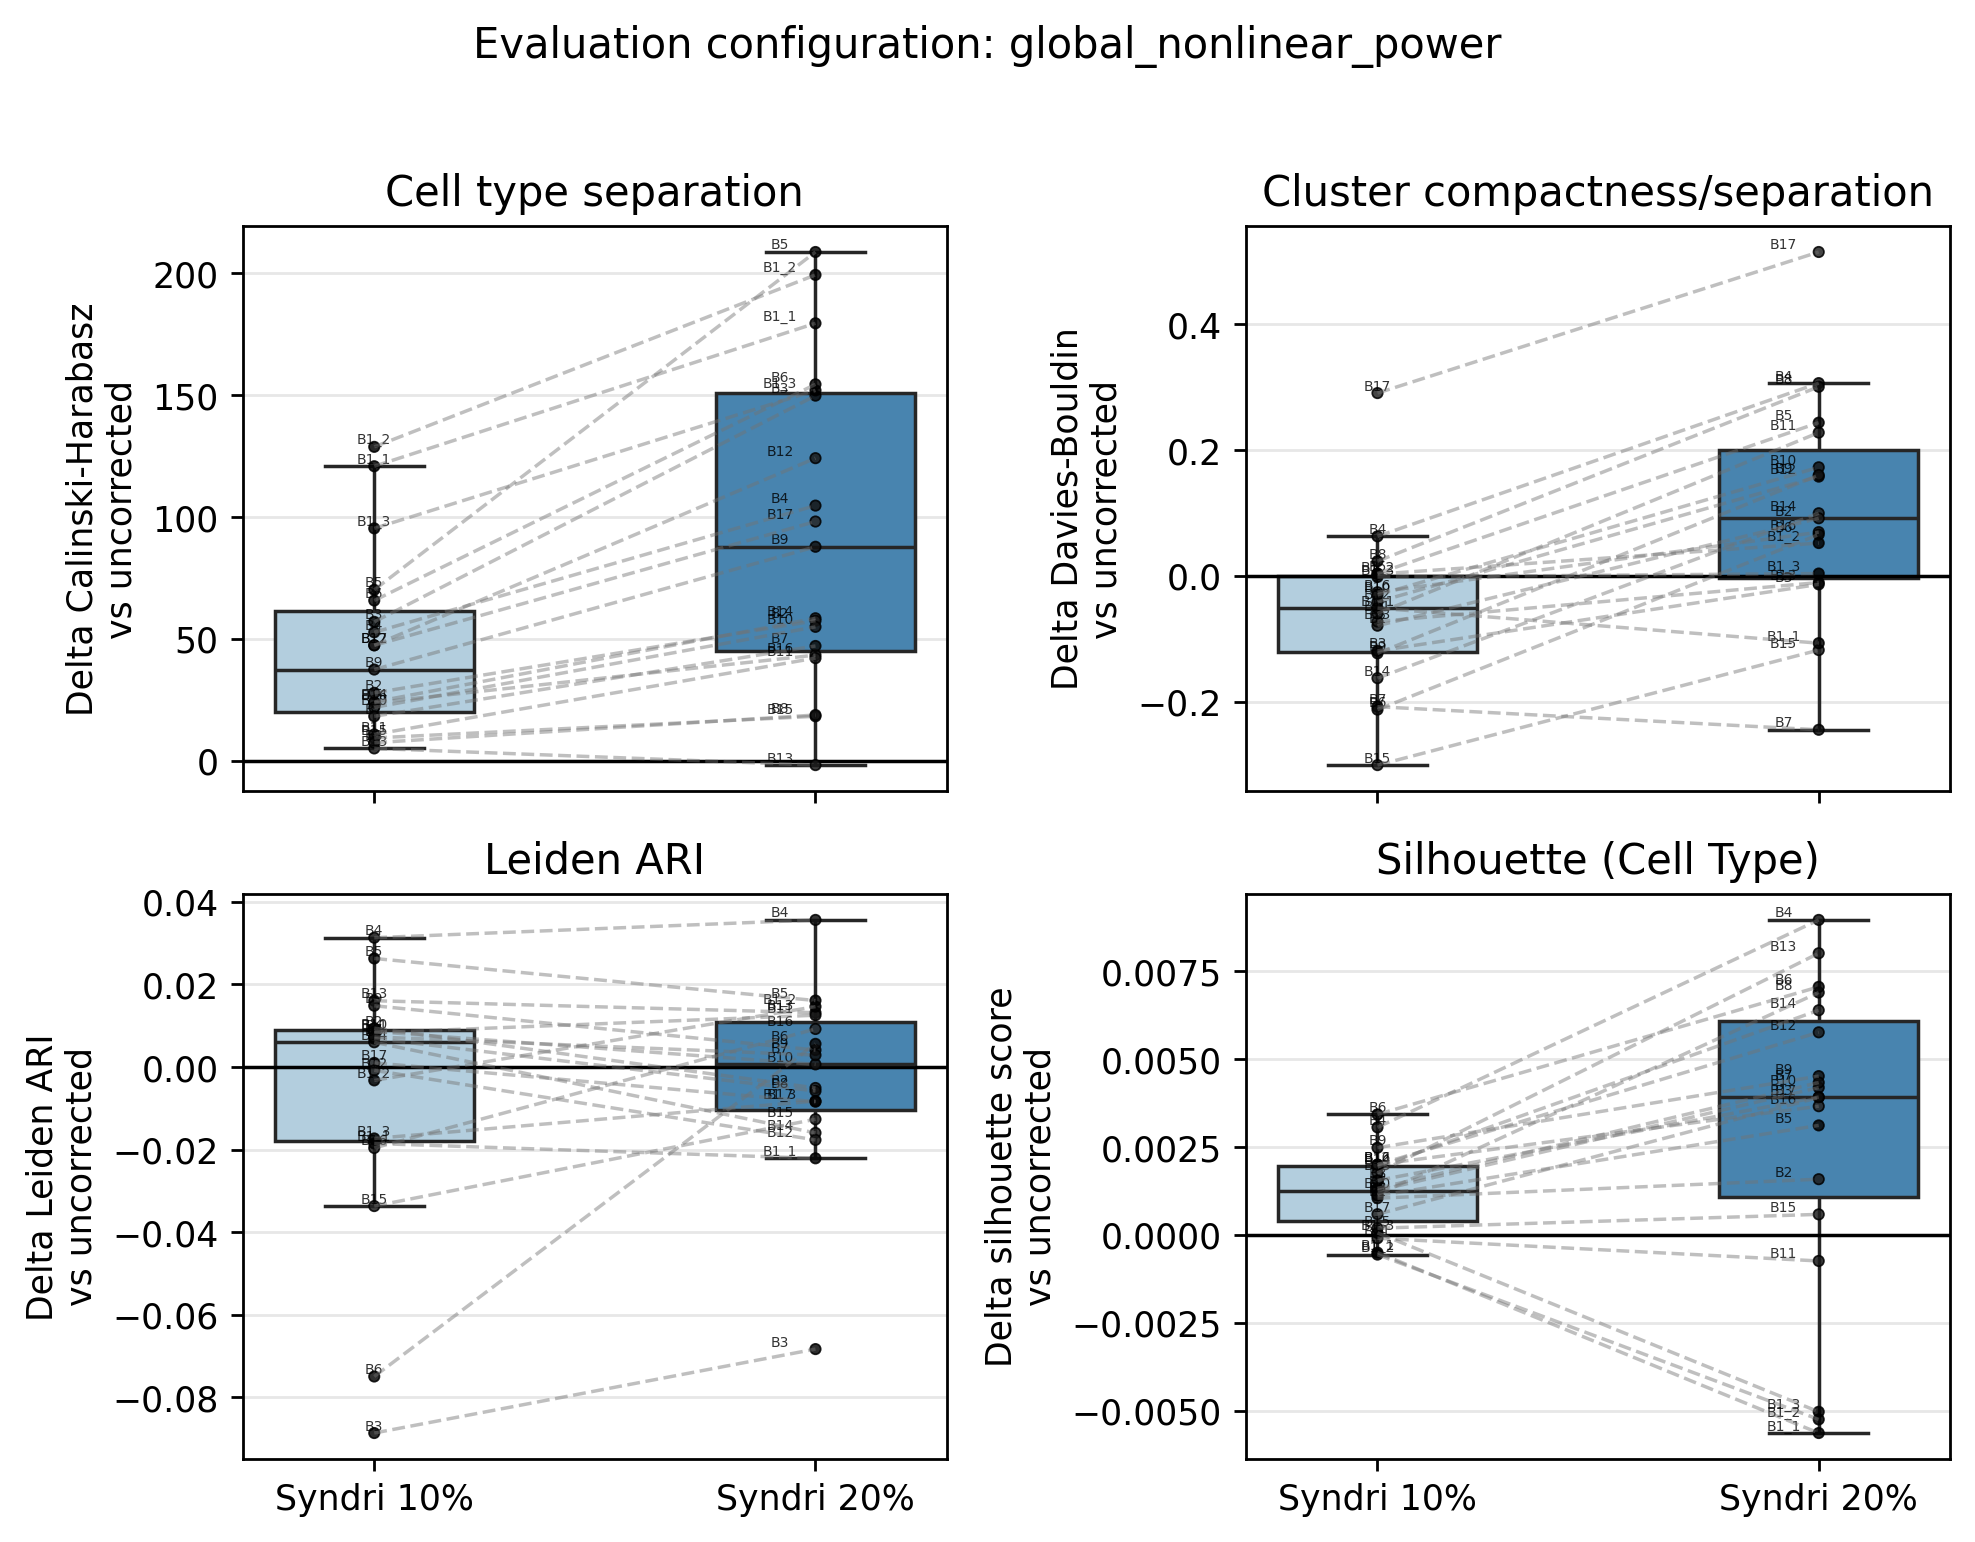

/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


GSM9509156_breast_breast_B17_B17_rctd_annotated_val_worstadj
GSM9509157_breast_breast_B16_B16_rctd_annotated_val_worstadj
GSM9509158_breast_breast_B15_B15_rctd_annotated_val_worstadj
GSM9509159_breast_breast_B14_B14_rctd_annotated_val_worstadj
GSM9509160_breast_breast_B2_B2_rctd_annotated_val_worstadj
GSM9509161_breast_breast_B13_B13_rctd_annotated_val_worstadj
GSM9509162_breast_breast_B12_B12_rctd_annotated_val_worstadj
GSM9509163_breast_breast_B11_B11_rctd_annotated_val_worstadj
GSM9509164_breast_breast_B10_B10_rctd_annotated_val_worstadj
GSM9509165_breast_breast_B4_B4_rctd_annotated_val_worstadj
GSM9509166_breast_breast_B9_B9_rctd_annotated_val_worstadj
GSM9509167_breast_breast_B8_B8_rctd_annotated_val_worstadj
GSM9509168_breast_breast_B7_B7_rctd_annotated_val_worstadj
GSM9509169_breast_breast_B6_B6_rctd_annotated_val_worstadj
GSM9509170_breast_breast_B3_B3_rctd_annotated_val_worstadj
GSM9509171_breast_breast_B5_B5_rctd_annotated_val_worstadj
GSM9509172_breast_breast_B1_B1_1_rctd_an

/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_2614836/3747604771.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2614836/3747604771.py:150: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


GSM9509156_breast_breast_B17_B17_rctd_annotated_val_worstadj
GSM9509157_breast_breast_B16_B16_rctd_annotated_val_worstadj
GSM9509158_breast_breast_B15_B15_rctd_annotated_val_worstadj
GSM9509159_breast_breast_B14_B14_rctd_annotated_val_worstadj
GSM9509160_breast_breast_B2_B2_rctd_annotated_val_worstadj
GSM9509161_breast_breast_B13_B13_rctd_annotated_val_worstadj
GSM9509162_breast_breast_B12_B12_rctd_annotated_val_worstadj
GSM9509163_breast_breast_B11_B11_rctd_annotated_val_worstadj
GSM9509164_breast_breast_B10_B10_rctd_annotated_val_worstadj
GSM9509165_breast_breast_B4_B4_rctd_annotated_val_worstadj
GSM9509166_breast_breast_B9_B9_rctd_annotated_val_worstadj
GSM9509167_breast_breast_B8_B8_rctd_annotated_val_worstadj
GSM9509168_breast_breast_B7_B7_rctd_annotated_val_worstadj
GSM9509169_breast_breast_B6_B6_rctd_annotated_val_worstadj
GSM9509170_breast_breast_B3_B3_rctd_annotated_val_worstadj
GSM9509171_breast_breast_B5_B5_rctd_annotated_val_worstadj
GSM9509172_breast_breast_B1_B1_1_rctd_an

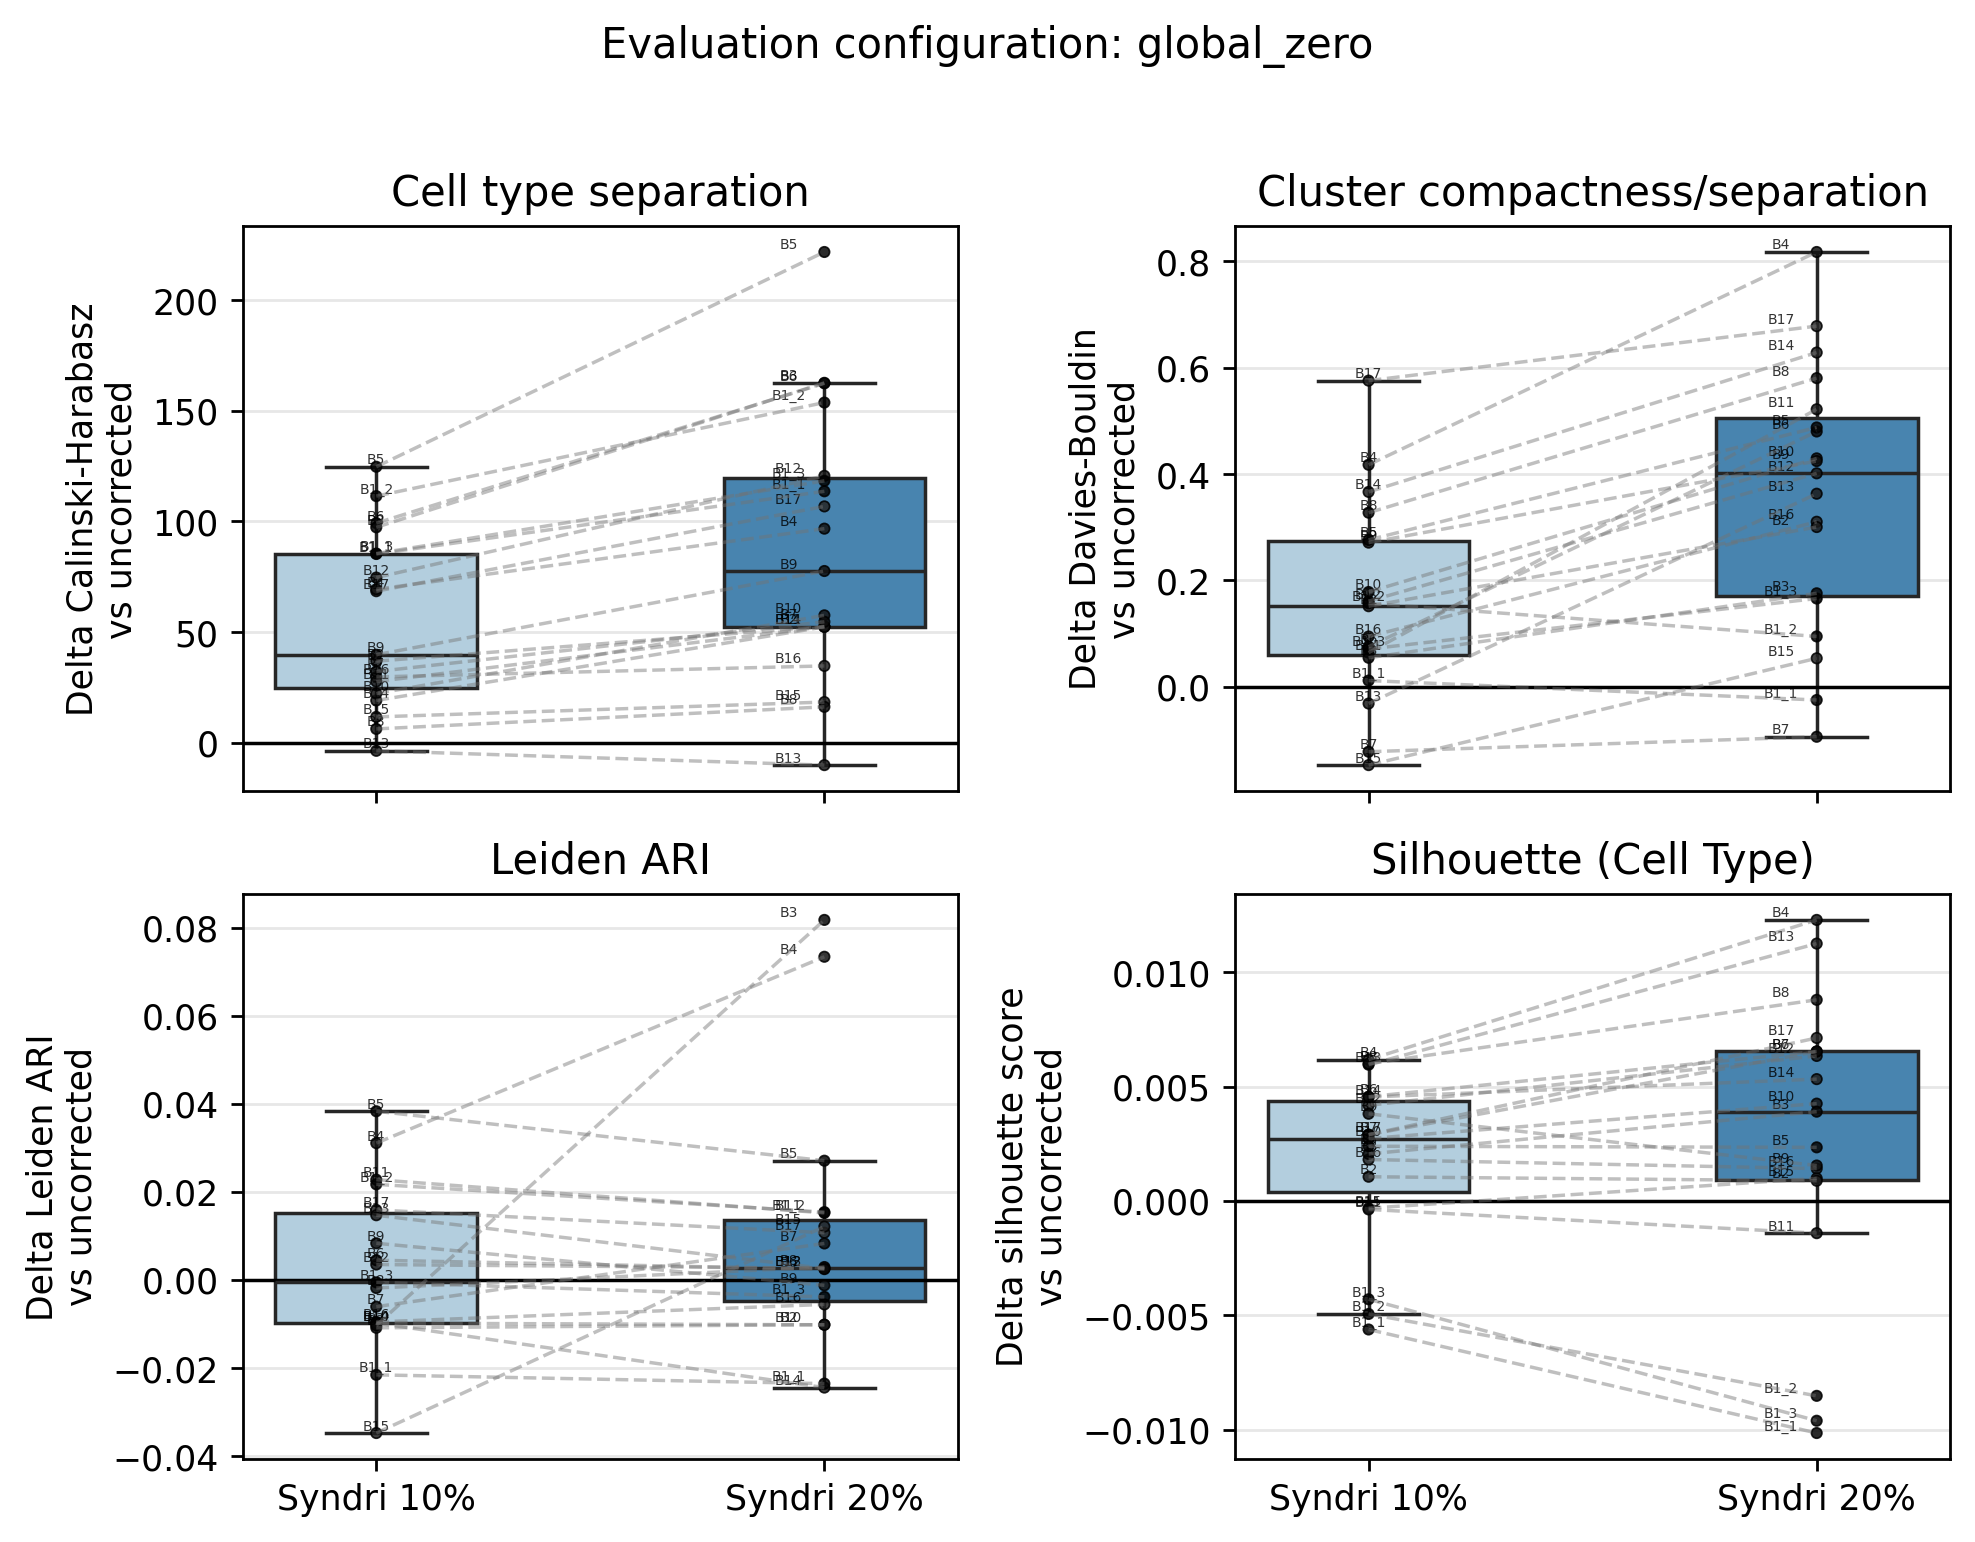

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text

baseline_case = "admixed"
method_cases = [
    # "cleaned_admixed_removed_frac_0.01",
    # "cleaned_admixed_removed_frac_0.02",
    # "cleaned_admixed_removed_frac_0.05",
    "cleaned_admixed_removed_frac_0.1",
    "cleaned_admixed_removed_frac_0.2",
    "SPLIT",
]

case_labels = {
    # "cleaned_admixed_removed_frac_0.01": "Syndri 1%" ,
    # "cleaned_admixed_removed_frac_0.02": "Syndri 2%",
    # "cleaned_admixed_removed_frac_0.05": "Syndri 5%",
    "cleaned_admixed_removed_frac_0.1": "Syndri 10%",
    "cleaned_admixed_removed_frac_0.2": "Syndri 20%",
    "SPLIT": "SPLIT",
}

metrics = [
    (
        "calinski_harabasz",
        "Cell type separation",
        "Delta Calinski-Harabasz\nvs uncorrected",
    ),
    (
        "davies_bouldin",
        "Cluster compactness/separation",
        "Delta Davies-Bouldin\nvs uncorrected",
    ),
    (
        "leiden_adjusted_rand_vs_label",
        "Leiden ARI",
        "Delta Leiden ARI\nvs uncorrected",
    ),
    (
        "silhouette_score",
        "Silhouette (Cell Type)",
        "Delta silhouette score\nvs uncorrected",
    ),
]

id_cols = ["tissue"]
# if "source_file" in sep_df.columns:
#     id_cols = ["source_file"]
# elif "filename" in sep_df.columns:
#     id_cols = ["filename"]

plot_base = sep_df[
    sep_df["case"].isin([baseline_case] + method_cases)
].copy()

plot_base["sample_id"] = plot_base[id_cols[0]].astype(str)
plot_base["tissue"] = plot_base["sample_id"].apply(
    lambda x: x.split("/")[-1].split(".")[0]
)
print(plot_base.head())
delta_frames = []

for metric, _, _ in metrics:
    wide = (
        plot_base
        .pivot_table(
            index=["eval_config", "sample_id", "tissue"],
            columns="case",
            values=metric,
            aggfunc="mean",
        )
        .reset_index()
    )

    for case in method_cases:
        required_cols = [
            "eval_config",
            "sample_id",
            "tissue",
            baseline_case,
            case,
        ]

        # Skip a method if it is entirely absent from the current data.
        if case not in wide.columns or baseline_case not in wide.columns:
            continue

        tmp = wide[required_cols].copy()
        tmp["case"] = case
        tmp["case_label"] = case_labels[case]
        tmp["metric"] = metric
        tmp["delta"] = tmp[case] - tmp[baseline_case]

        delta_frames.append(
            tmp[
                [
                    "eval_config",
                    "sample_id",
                    "tissue",
                    "case",
                    "case_label",
                    "metric",
                    "delta",
                ]
            ]
        )

delta_df = pd.concat(delta_frames, ignore_index=True)

delta_df["case_label"] = pd.Categorical(
    delta_df["case_label"],
    categories=[case_labels[c] for c in method_cases],
    ordered=True,
)

palette = {
    "Syndri 20%": sns.color_palette("Blues", n_colors=4)[-1],
    "SPLIT": "purple",
}

palette = dict(
    zip(
        [case_labels[c] for c in method_cases],
        sns.color_palette(
            "Blues",
            n_colors=len(method_cases[:-1]),
        ) + ["purple"],
    )
)


def plot_metric_delta(ax, data, metric, title, ylabel):
    sub = data[data["metric"] == metric].copy()
    sub = sub.dropna(subset=["delta"])
    # print(sub.head())
    sns.boxplot(    
        data=sub,
        x="case_label",
        y="delta",
        order=[case_labels[c] for c in method_cases],
        palette=palette,
        width=0.45,
        showfliers=False,
        ax=ax,
    )

    sns.stripplot(
        data=sub,
        x="case_label",
        y="delta",
        order=[case_labels[c] for c in method_cases],
        hue="tissue",
        dodge=False,
        jitter=0,
        size=3,
        linewidth=0.5,
        edgecolor="black",
        alpha=0.85,
        ax=ax,
        legend=False,
        color="black",
    )

    x_lookup = {
        label: i
        for i, label in enumerate(
            [case_labels[c] for c in method_cases]
        )
    }

    label_offsets = {
        "Syndri 20%": -0.08,
        "SPLIT": 0.08,
    }

    texts = []

    for _, row in sub.iterrows():
        # print(row["tissue"])

        x = (
            x_lookup[row["case_label"]]
            + label_offsets.get(row["case_label"], 0.0)
        )
        y = row["delta"]

        # if row["tissue"].split('_')[3] == 'B1':
        print(row['tissue'])
        texts.append(
            ax.text(
                x,
                y,
                "_".join(row["tissue"].split("_")[4:-4]),
                # row['tissue'],
                fontsize=4,
                ha="center",
                va="bottom",
                alpha=0.8,
            )
        )
        # print("_".join(row["tissue"].split("_")[4:-7]))

    # adjust_text(texts,arrowprops=dict(arrowstyle="->", color='red', lw=0.5))

    paired = (
        sub
        .pivot_table(
            index=["sample_id", "tissue"],
            columns="case_label",
            values="delta",
            aggfunc="mean",
            observed=False,
        )
        .reset_index()
    )

    method_labels = [case_labels[c] for c in method_cases]

    for _, sample in paired.iterrows():
        available_labels = [
            label
            for label in method_labels
            if label in paired.columns and pd.notna(sample[label])
        ]

        if len(available_labels) >= 2:
            xs = [x_lookup[label] for label in available_labels]
            ys = [sample[label] for label in available_labels]

            ax.plot(
                xs,
                ys,
                color="0.45",
                alpha=0.45,
                linewidth=1,
                zorder=5,
                linestyle="--",
            )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", alpha=0.3)


eval_configs = delta_df["eval_config"].dropna().unique()

for eval_config in eval_configs:
    config_df = delta_df[
        delta_df["eval_config"] == eval_config
    ].copy()

    fig, axes_grid = plt.subplots(
        2,
        2,
        figsize=(8, 6),
        sharex=True,
        dpi=250,
    )
    axes = axes_grid.flat

    for ax, (metric, title, ylabel) in zip(axes, metrics):
        plot_metric_delta(
            ax=ax,
            data=config_df,
            metric=metric,
            title=title,
            ylabel=ylabel,
        )

    fig.suptitle(
        f"Evaluation configuration: {eval_config}",
        fontsize=12,
        y=1.02,
    )

    plt.tight_layout()
    plt.show()

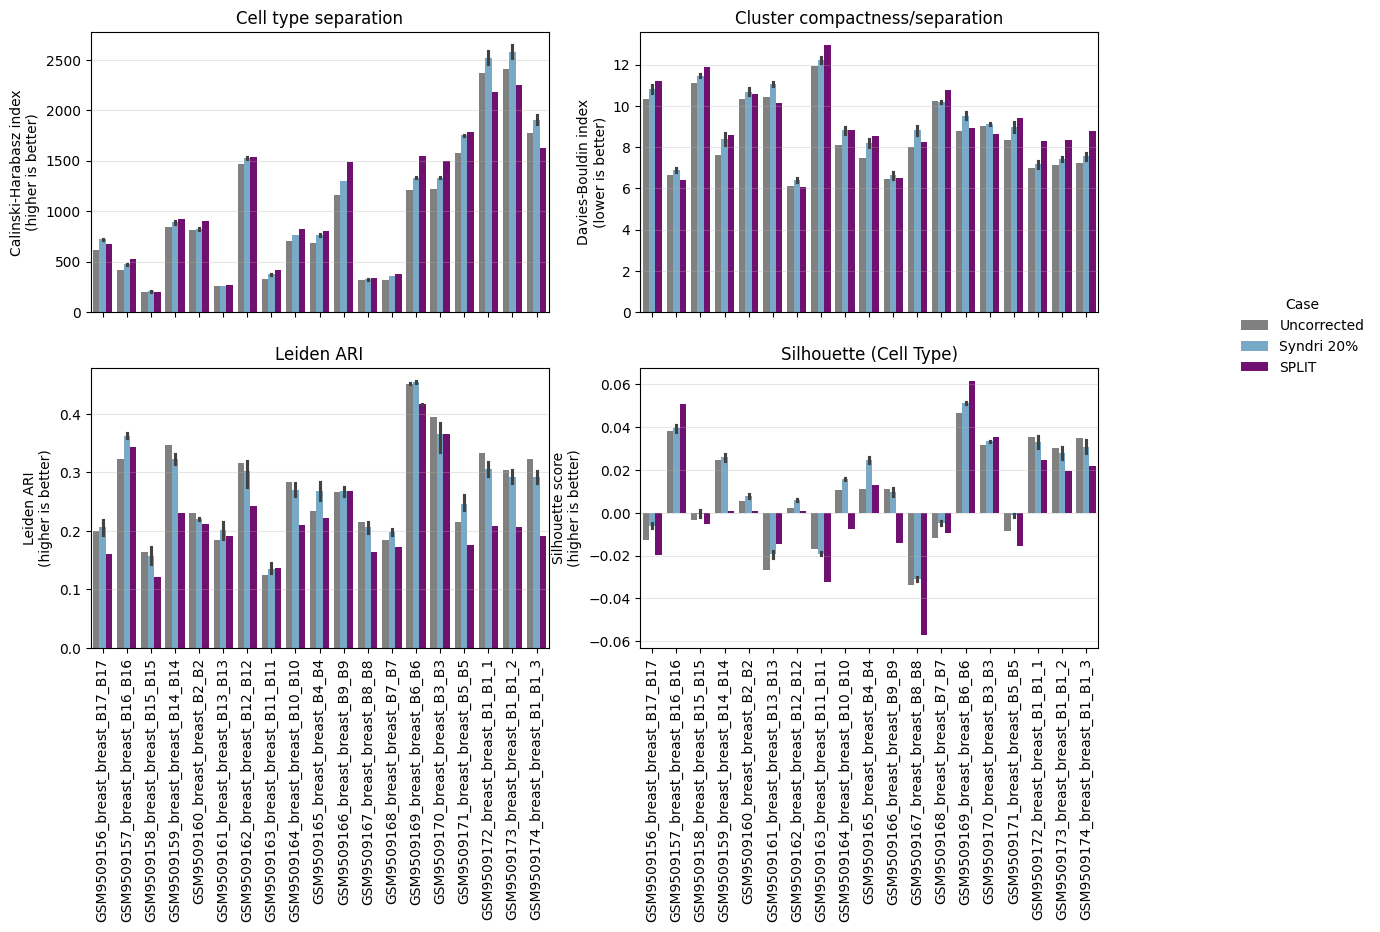

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

case_order = [
    "admixed",
    # "cleaned_admixed_removed_frac_0.01",
    # "cleaned_admixed_removed_frac_0.02",
    # "cleaned_admixed_removed_frac_0.05",
    # "cleaned_admixed_removed_frac_0.1",
    "cleaned_admixed_removed_frac_0.2",
    "SPLIT",
]

case_labels = {
    "admixed": "Uncorrected",
    # "cleaned_admixed_removed_frac_0.01": "Syndri 1%" ,
    # "cleaned_admixed_removed_frac_0.02": "Syndri 2%",
    # "cleaned_admixed_removed_frac_0.05": "Syndri 5%",
    # "cleaned_admixed_removed_frac_0.1": "Syndri 10%",
    "cleaned_admixed_removed_frac_0.2": "Syndri 20%",
    "SPLIT":"SPLIT"
}

plot_df = sep_df[
    sep_df["case"].isin(case_order)
].copy()

plot_df["case"] = pd.Categorical(
    plot_df["case"],
    categories=case_order,
    ordered=True,
)

plot_df["case_label"] = plot_df["case"].map(case_labels)
plot_df["tissue"] = plot_df["tissue"].astype(str).apply(lambda x: x.split('/')[-1].split('.')[0])

tissue_order = sorted(plot_df["tissue"].dropna().unique())
palette = dict(zip(
    [case_labels[c] for c in case_order],
    ['gray'] + sns.color_palette("Blues", n_colors=len(case_order[1:-1]))+['purple'],
))

fig, axes_grid = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
axes = axes_grid.flat


def plot_metric(ax, metric, title, ylabel):
    sns.barplot(
        data=plot_df,
        x="tissue",
        y=metric,
        hue="case_label",
        order=tissue_order,
        hue_order=[case_labels[c] for c in case_order],
        palette=palette,
        dodge=True,
        ax=ax,
        legend=False,
    )
    
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    # ax.set_xticklabels(ax.get_xticklabels(),ha='right',rotation=45)
    ax.tick_params(axis="x", rotation=90)
    # if len(ax.get_xticklabels())>0:
    #     ax.get_xticklabels()[10].set_color("red")
    ax.grid(True, axis="y", alpha=0.3)


plot_metric(
    axes[0],
    "calinski_harabasz",
    "Cell type separation",
    "Calinski-Harabasz index\n(higher is better)",
)

plot_metric(
    axes[1],
    "davies_bouldin",
    "Cluster compactness/separation",
    "Davies-Bouldin index\n(lower is better)",
)

plot_metric(
    axes[2],
    "leiden_adjusted_rand_vs_label",
    "Leiden ARI",
    "Leiden ARI\n(higher is better)",
)

plot_metric(
    axes[3],
    "silhouette_score",
    "Silhouette (Cell Type)",
    "Silhouette score\n(higher is better)",
)

handles, legend_labels = axes[0].get_legend_handles_labels()
if not handles:
    handles, legend_labels = axes[0].containers, [case_labels[c] for c in case_order]

fig.legend(
    handles=handles,
    labels=legend_labels,
    title="Case",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    frameon=False,
)

# fig.tight_layout(rect=[0, 0, 0.86, 1])
plt.show()


In [ ]:
teff_df[
    (teff_df["target_cell_type_i"].str.contains("T", na=False))
     & (teff_df["contaminating_cell_type_j"] == "malignant cell")]
tcell_df['case'] = tcell_df['condition']
tcell_df['case'].unique()

array(['uncorrected', 'cleaned_admixed_removed_frac_0.01',
       'cleaned_admixed_removed_frac_0.02',
       'cleaned_admixed_removed_frac_0.05',
       'cleaned_admixed_removed_frac_0.1',
       'cleaned_admixed_removed_frac_0.2', 'split'], dtype=object)

In [ ]:
case_order = [
    "uncorrected",
    # "cleaned_admixed_removed_frac_0.01",
    # "cleaned_admixed_removed_frac_0.02",
    # "cleaned_admixed_removed_frac_0.05",
    "cleaned_admixed_removed_frac_0.1",
    # "cleaned_expression",
    "split",
]

case_labels = {
    "uncorrected": "Uncorrected",
    # "cleaned_admixed_removed_frac_0.01": "Cleaned 1%" ,
    # "cleaned_admixed_removed_frac_0.02": "Cleaned 2%",
    # "cleaned_admixed_removed_frac_0.05": "Cleaned 5%",
    "cleaned_admixed_removed_frac_0.1": "Syndri",
    # "cleaned_expression": "Syndri",
    "split":"SPLIT"
}
condition_order = ["Uncorrected", "Syndri", "SPLIT"]
condition_palette = {
    "Uncorrected": "#8c8c8c",
    "Syndri": "#1f77b4",
    "SPLIT": "#b937ec",
}
condition_palette = dict(zip(
    [c for c in condition_order],
    ['gray'] + sns.color_palette("Blues", n_colors=len(condition_order[1:-1]))+['purple'],
))
plot_df = tcell_df[
    tcell_df["case"].isin(case_order)
].copy()

plot_df["case"] = pd.Categorical(
    plot_df["case"],
    categories=case_order,
    ordered=True,
)

plot_df["case_label"] = plot_df["case"].map(case_labels)
plot_df["tissue"] = plot_df["tissue"].astype(str).apply(lambda x: x.split('/')[-1].split('.')[0])
# print(plot_df['tissue'])
tissue_order = sorted(plot_df["tissue"].dropna().unique())
palette = dict(zip(
    [case_labels[c] for c in case_order],
    ['gray'] + sns.color_palette("Blues", n_colors=len(case_order[1:-1]))+['purple'],
))

tcell_malignant_specificity = tcell_df[
    (tcell_df["target_cell_type_i"].str.contains("T", na=False))
    & (tcell_df["contaminating_cell_type_j"] == "malignant cell")
].copy()

plot_df = plot_df[(plot_df["target_cell_type_i"].str.contains("T", na=False))
    & (plot_df["contaminating_cell_type_j"] == "malignant cell")]
import json
import pandas as pd

def parse_gene_list(x):
    if isinstance(x, list):
        return x
    if pd.isna(x):
        return []
    return json.loads(x)

plot_df = plot_df.copy()

plot_df["overlap_gene_list"] = (
    plot_df["overlap_genes"]
    .apply(parse_gene_list)
)

# Sanity check
assert (
    plot_df["overlap_gene_list"].str.len()
    == plot_df["marker_overlap_n"]
).all()
ensembl_to_symbol = st_data.uns["gene_mapping:ensembl_to_symbol"]

plot_df["overlap_gene_symbols"] = (
    plot_df["overlap_gene_list"]
    .apply(
        lambda genes: [
            ensembl_to_symbol.get(gene, gene)[0]
            for gene in genes
        ]
    )
)
print(plot_df[['overlap_genes','overlap_gene_symbols']])
plot_df["overlap_label"] = (
    plot_df["overlap_gene_symbols"]
    .apply(lambda genes: ", ".join(genes))
)

# fig, ax = plt.subplots(1, 1, figsize=(7, 5))
# sns.swarmplot(
#     data=plot_df,
#     x="case_label",
#     y="marker_overlap_n",
#     hue="target_cell_type_i",
#     # hue_order=condition_order,
#     # palette=condition_palette,
#     dodge=True,
#     # ci=None,
#     ax=ax,
# )
g = sns.catplot(
    data=plot_df,
    x="case_label",
    y="marker_overlap_n",
    col="target_cell_type_i",
    kind="strip",
    jitter=0.15,
    alpha=0.7,
    size=5,
    col_wrap=3,
    height=3.5,
    aspect=0.9
)


ax.set_title("T cell malignant-marker overlap")
ax.set_xlabel("")
ax.set_ylabel("Marker overlap")
ax.set_yticks(np.arange(0,4,1))
ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right')
# ax.tick_params(axis="x", rotation=45)

# sns.stripplot(data=plot_df,
#     x="target_cell_type_i",
#     y="marker_overlap_n",
#     hue="case_label",
#     hue_order=condition_order,
#     color='black',
#     # ci=None,
#     jitter=0.1,
#     alpha=0.7,
#     ax=ax,
#     dodge=True,
# )


ax.legend(title="T-Cell Subtype",bbox_to_anchor=(1,1.05))


# tcell_malignant_effect = tcell_specificity_effect[
#     tcell_specificity_effect["contaminating_cell_type_j"] == "malignant cell"
# ].copy()
# sns.barplot(
#     data=tcell_malignant_effect,
#     x="target_cell_type_i",
#     y="delta_purified_minus_cleaned",
#     color=condition_palette[purified_condition_label],
#     ci=None,
#     ax=axes[1],
# )
# axes[1].axhline(0, color="black", linewidth=1)
# axes[1].set_title("SPLIT minus cleaned expression")
# axes[1].set_xlabel("")
# axes[1].set_ylabel("Delta mean marker overlap")
# axes[1].tick_params(axis="x", rotation=45)

# plt.show()


NameError: name 'st_data' is not defined

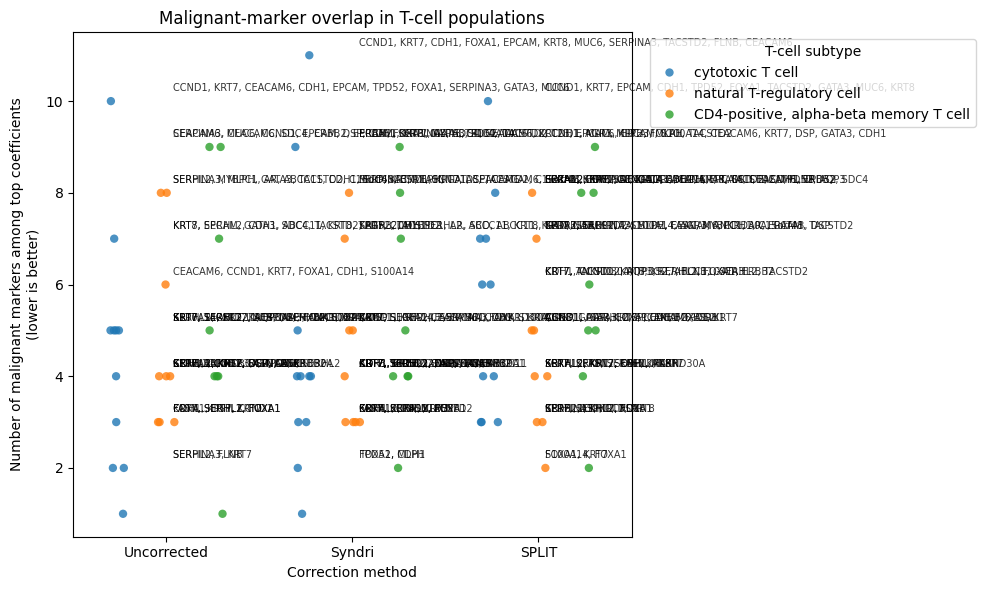

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator
condition_order = [
    "Uncorrected",
    "Syndri",
    "SPLIT"
]

cell_type_order = [
    "cytotoxic T cell",
    "natural T-regulatory cell",
    "CD4-positive, alpha-beta memory T cell"
]
fig, ax = plt.subplots(figsize=(10, 6))

sns.stripplot(
    data=plot_df,
    x="case_label",
    y="marker_overlap_n",
    hue="target_cell_type_i",
    order=condition_order,
    hue_order=cell_type_order,
    dodge=True,
    jitter=0.15,
    size=6,
    alpha=0.8,
    ax=ax
)

ax.set_title(
    "Malignant-marker overlap in T-cell populations"
)

ax.set_xlabel("Correction method")

ax.set_ylabel(
    "Number of malignant markers among top coefficients\n"
    "(lower is better)"
)

ax.yaxis.set_major_locator(
    MaxNLocator(integer=True)
)

ax.legend(
    title="T-cell subtype",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
x_positions = {
    "Uncorrected": 0,
    "Syndri": 1,
    "SPLIT": 2
}

annot_df = plot_df[
    plot_df["marker_overlap_n"] >= 2
].copy()

for _, row in annot_df.iterrows():

    ax.annotate(
        row["overlap_label"],
        xy=(
            x_positions[row["case_label"]],
            row["marker_overlap_n"]
        ),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=7,
        alpha=0.8
    )
plt.tight_layout()

In [ ]:
def parse_gene_list(x):
    if isinstance(x, list):
        return x
    if pd.isna(x):
        return []
    return json.loads(x)

plot_df = plot_df.copy()

plot_df["overlap_gene_list"] = (
    plot_df["overlap_genes"]
    .apply(parse_gene_list)
)

# Sanity check
assert (
    plot_df["overlap_gene_list"].str.len()
    == plot_df["marker_overlap_n"]
).all()
ensembl_to_symbol = st_data.uns["gene_mapping:ensembl_to_symbol"]

plot_df["overlap_gene_symbols"] = (
    plot_df["overlap_gene_list"]
    .apply(
        lambda genes: [
            ensembl_to_symbol.get(gene, gene)[0]
            for gene in genes
        ]
    )
)
print(plot_df[['overlap_genes','overlap_gene_symbols']])
plot_df["overlap_label"] = (
    plot_df["overlap_gene_symbols"]
    .apply(lambda genes: ", ".join(genes))
)

                                          overlap_genes  \
65                                  ["ENSG00000076554"]   
377              ["ENSG00000076554", "ENSG00000039068"]   
533   ["ENSG00000076554", "ENSG00000039068", "ENSG00...   
31                                  ["ENSG00000129514"]   
56    ["ENSG00000189334", "ENSG00000135480", "ENSG00...   
...                                                 ...   
696   ["ENSG00000183569", "ENSG00000169710", "ENSG00...   
713   ["ENSG00000121270", "ENSG00000183569", "ENSG00...   
927   ["ENSG00000183569", "ENSG00000196091", "ENSG00...   
988   ["ENSG00000183569", "ENSG00000135480", "ENSG00...   
1005  ["ENSG00000121270", "ENSG00000183569", "ENSG00...   

                                   overlap_gene_symbols  
65                                              [TPD52]  
377                                       [TPD52, CDH1]  
533                                  [TPD52, CDH1, DSP]  
31                                              [FOXA1]  
5

In [ ]:
plot_df[plot_df['condition']=='uncorrected']

,sample,target_cell_type_i,contaminating_cell_type_j,n_target_cells_total,n_proximal_to_j,n_distal_to_j,n_fit_cells,top_n,marker_overlap_n,marker_overlap_frac,...,cell_type_specific_removal,group_admix_prob_thresholds,group_probability_removal_scales,group_achieved_removed_fractions,error,case,case_label,overlap_gene_list,overlap_gene_symbols,overlap_label
65,st,cytotoxic T cell,malignant cell,627,146,481,627,20,1,0.05,...,True,NaN,NaN,NaN,NaN,uncorrected,Uncorrected,[ENSG00000076554],[TPD52],TPD52
31,st,"CD4-positive, alpha-beta memory T cell",malignant cell,2174,207,1967,2174,20,1,0.05,...,True,NaN,NaN,NaN,NaN,uncorrected,Uncorrected,[ENSG00000129514],[FOXA1],FOXA1
56,st,cytotoxic T cell,malignant cell,2820,658,2162,2820,20,5,0.25,...,True,NaN,NaN,NaN,NaN,uncorrected,Uncorrected,"[ENSG00000189334, ENSG00000135480, ENSG0000019...","[S100A14, KRT7, SERPINA3, ANKRD30A, DSP]","S100A14, KRT7, SERPINA3, ANKRD30A, DSP"
158,st,natural T-regulatory cell,malignant cell,673,104,569,673,20,4,0.20,...,True,NaN,NaN,NaN,NaN,uncorrected,Uncorrected,"[ENSG00000189334, ENSG00000173467, ENSG0000010...","[S100A14, AGR3, GATA3, ERBB2]","S100A14, AGR3, GATA3, ERBB2"
57,st,natural T-regulatory cell,malignant cell,552,226,326,552,20,8,0.40,...,True,NaN,NaN,NaN,NaN,uncorrected,Uncorrected,"[ENSG00000196136, ENSG00000115648, ENSG0000010...","[SERPINA3, MLPH, GATA3, TACSTD2, C15orf48, ESR...","SERPINA3, MLPH, GATA3, TACSTD2, C15orf48, ESR1..."
63,st,cytotoxic T cell,malignant cell,751,208,543,751,20,7,0.35,...,True,NaN,NaN,NaN,NaN,uncorrected,Uncorrected,"[ENSG00000170421, ENSG00000119888, ENSG0000010...","[KRT8, EPCAM, GATA3, SDC4, TACSTD2, AGR3, CDH1]","KRT8, EPCAM, GATA3, SDC4, TACSTD2, AGR3, CDH1"
70,st,"CD4-positive, alpha-beta memory T cell",malignant cell,422,141,281,422,20,9,0.45,...,True,NaN,NaN,NaN,NaN,uncorrected,Uncorrected,"[ENSG00000196136, ENSG00000086548, ENSG0000012...","[SERPINA3, CEACAM6, SDC4, ERBB2, EPCAM, FOXA1,...","SERPINA3, CEACAM6, SDC4, ERBB2, EPCAM, FOXA1, ..."
55,st,cytotoxic T cell,malignant cell,1174,166,1008,1174,20,2,0.10,...,True,NaN,NaN,NaN,NaN,uncorrected,Uncorrected,"[ENSG00000196136, ENSG00000135480]","[SERPINA3, KRT7]","SERPINA3, KRT7"
33,st,cytotoxic T cell,malignant cell,5545,3063,2482,5545,20,10,0.50,...,True,NaN,NaN,NaN,NaN,uncorrected,Uncorrected,"[ENSG00000110092, ENSG00000135480, ENSG0000008...","[CCND1, KRT7, CEACAM6, CDH1, EPCAM, TPD52, FOX...","CCND1, KRT7, CEACAM6, CDH1, EPCAM, TPD52, FOXA..."
88,st,natural T-regulatory cell,malignant cell,1277,513,764,1277,20,6,0.30,...,True,NaN,NaN,NaN,NaN,uncorrected,Uncorrected,"[ENSG00000086548, ENSG00000110092, ENSG0000013...","[CEACAM6, CCND1, KRT7, FOXA1, CDH1, S100A14]","CEACAM6, CCND1, KRT7, FOXA1, CDH1, S100A14"


['GSM9509159_breast_breast_B14_B14' 'GSM9509162_breast_breast_B12_B12'
 'GSM9509163_breast_breast_B11_B11' 'GSM9509164_breast_breast_B10_B10'
 'GSM9509166_breast_breast_B9_B9' 'GSM9509169_breast_breast_B6_B6'
 'GSM9509170_breast_breast_B3_B3' 'GSM9509171_breast_breast_B5_B5'
 'GSM9509172_breast_breast_B1_B1_1' 'GSM9509173_breast_breast_B1_B1_2'
 'GSM9509174_breast_breast_B1_B1_3']


/tmp/ipykernel_3127934/1365765038.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(
/tmp/ipykernel_3127934/1365765038.py:42: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(


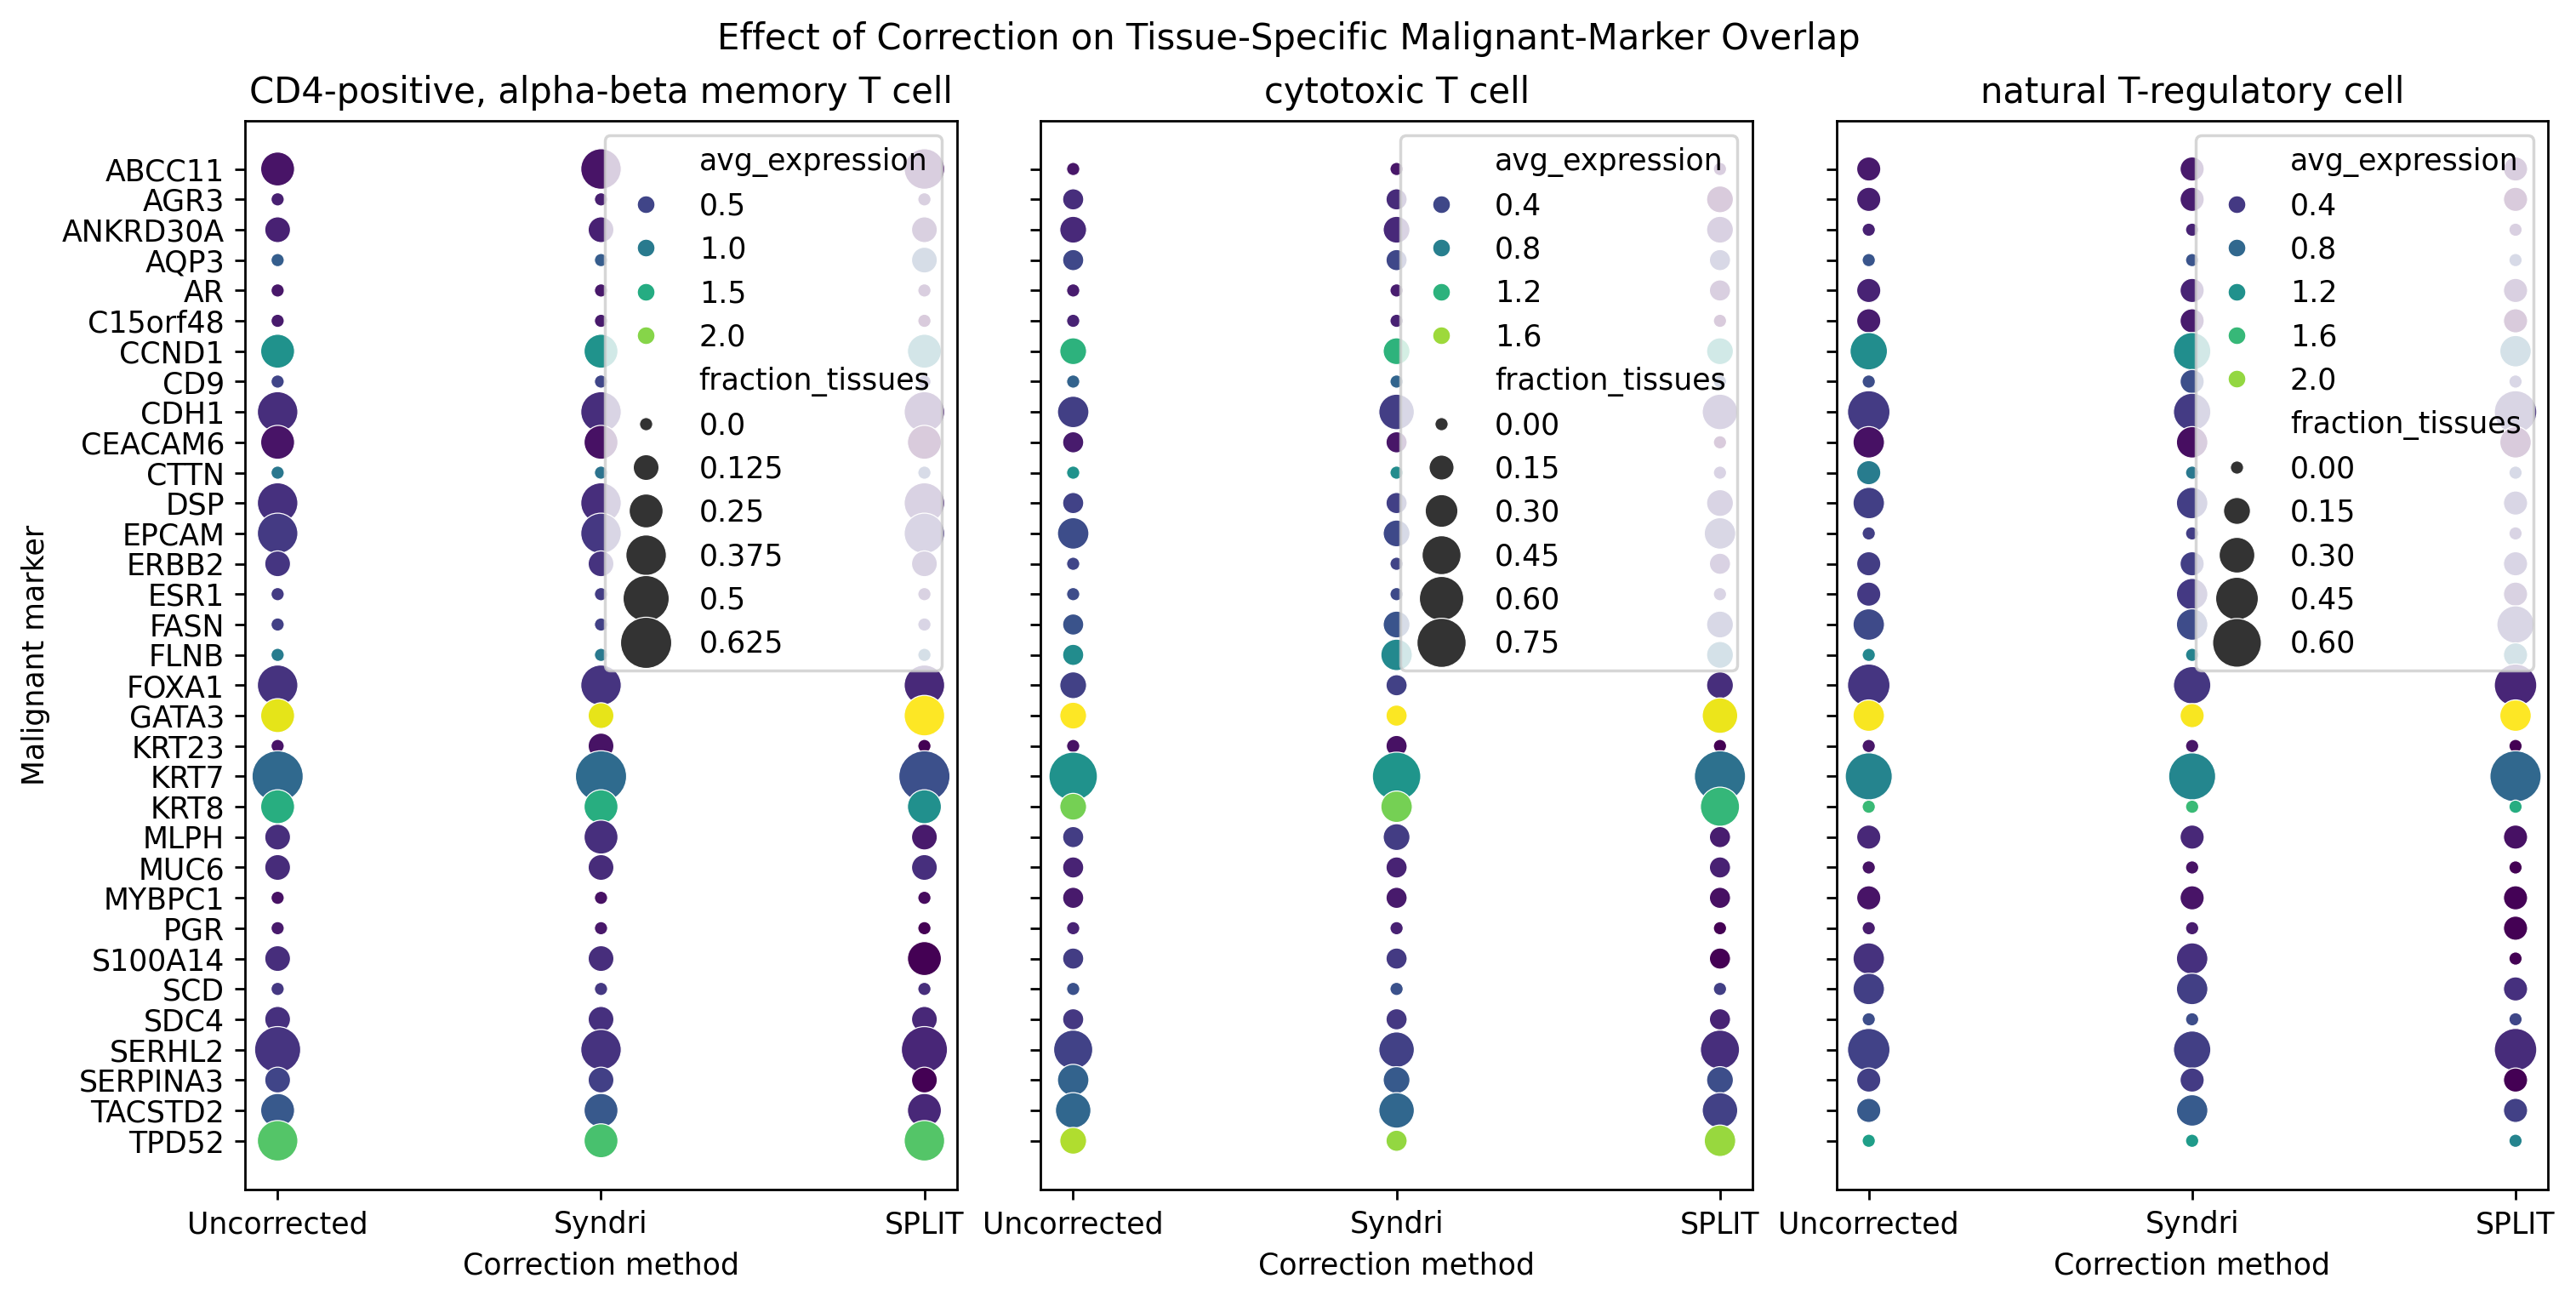

In [ ]:
subset_df = plot_df.copy()#[plot_df['tissue'].str.contains('_B1_')]
print(subset_df['tissue'].unique())
marker_long = (
    subset_df[
        [
            "tissue",
            "target_cell_type_i",
            "case_label",
            "overlap_gene_symbols"
        ]
    ]
    .explode("overlap_gene_symbols")
    .rename(
        columns={
            "overlap_gene_symbols": "marker"
        }
    )
    .dropna(
        subset=["marker"]
    )
)
marker_counts = (
    marker_long
    .groupby(
        [
            "target_cell_type_i",
            "case_label",
            "marker"
        ]
    )
    .agg(
        n_tissues_with_marker=(
            "tissue",
            "nunique"
        )
    )
    .reset_index()
)

n_tissues = (
    plot_df
    .groupby(
        [
            "target_cell_type_i",
            "case_label"
        ]
    )
    .agg(
        n_tissues=(
            "tissue",
            "nunique"
        )
    )
    .reset_index()
)

marker_counts = marker_counts.merge(
    n_tissues,
    on=[
        "target_cell_type_i",
        "case_label"
    ]
)

marker_counts["fraction_tissues"] = (
    marker_counts["n_tissues_with_marker"]
    / marker_counts["n_tissues"]
)
top_gene_profiles['case_label']= top_gene_profiles['condition'].map(case_labels)
# top_gene_profiles = top_gene_profiles.drop(columns=['case'])
avg_profiles = top_gene_profiles[['tissue','case_label','cell_type','gene_symbol','mean_expression']].groupby(['case_label','cell_type','gene_symbol'])['mean_expression'].mean().reset_index(name='avg_expression')

marker_counts = marker_counts.merge(avg_profiles,left_on=['target_cell_type_i','case_label','marker'],right_on=['cell_type','case_label','gene_symbol'],how='left')
cell_types = (
    marker_counts[
        "target_cell_type_i"
    ]
    .unique()
)

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(cell_types),
    figsize=(4 * len(cell_types), 6),
    constrained_layout=True,
    sharey=True,
    sharex=True,
    dpi=250
)

for ax, cell_type in zip(
    axes,
    cell_types
):

    current = marker_counts[
        marker_counts[
            "target_cell_type_i"
        ] == cell_type
    ]

    # matrix = (
    #     current
    #     .pivot(
    #         index="marker",
    #         columns="case_label",
    #         values="avg_expression"
    #     )
    #     .reindex(
    #         columns=condition_order
    #     )
    #     .fillna(0)
    # )

    # g= sns.heatmap(
    #     matrix,
    #     annot=True,
    #     fmt=".2f",
    #     vmin=0,
    #     vmax=1,
    #     ax=ax,
    #     # cbar=False
    # )

    # plt.figure(figsize=(6, 4))
    sns.scatterplot(
        data=current,
        x="case_label",
        y="marker",
        size="fraction_tissues",  # Maps to dot size
        hue="avg_expression",     # Maps to color gradient
        sizes=(20, 300),           # Scale of the dot sizes
        palette="viridis",        # Color palette
        ax=ax,
    )

    # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    # plt.tight_layout()
    # plt.show()
    ax.set_title(cell_type)

    ax.set_xlabel(
        "Correction method"
    )

    ax.set_ylabel(
        "Malignant marker"
    )
# cbar = fig.colorbar(axes[0].collections[0], cax=axes[2])
# cbar.set_label('Shared Data Value')
fig.suptitle('Effect of Correction on Tissue-Specific Malignant-Marker Overlap')

plt.show()

In [ ]:
marker_counts

,target_cell_type_i,case_label,marker,n_tissues_with_marker,n_tissues,fraction_tissues
0,"CD4-positive, alpha-beta memory T cell",Uncorrected,ABCC11,2,8,0.250000
1,"CD4-positive, alpha-beta memory T cell",Uncorrected,AGR3,0,8,0.000000
2,"CD4-positive, alpha-beta memory T cell",Uncorrected,ANKRD30A,1,8,0.125000
3,"CD4-positive, alpha-beta memory T cell",Uncorrected,AQP3,0,8,0.000000
4,"CD4-positive, alpha-beta memory T cell",Uncorrected,AR,0,8,0.000000
...,...,...,...,...,...,...
292,natural T-regulatory cell,SPLIT,SDC4,0,9,0.000000
293,natural T-regulatory cell,SPLIT,SERHL2,4,9,0.444444
294,natural T-regulatory cell,SPLIT,SERPINA3,1,9,0.111111
295,natural T-regulatory cell,SPLIT,TACSTD2,1,9,0.111111


In [ ]:
top_gene_profiles['case_label']= top_gene_profiles['condition'].map(case_labels)
# top_gene_profiles = top_gene_profiles.drop(columns=['case'])
avg_profiles = top_gene_profiles[['tissue','case_label','cell_type','gene_symbol','mean_expression']].groupby(['case_label','cell_type','gene_symbol'])['mean_expression'].mean().reset_index(name='avg_expression')
avg_profiles
marker_counts.merge(avg_profiles,left_on=['target_cell_type_i','case_label','marker'],right_on=['cell_type','case_label','gene_symbol'],how='left')

,target_cell_type_i,case_label,marker,n_tissues_with_marker,n_tissues,fraction_tissues,cell_type,gene_symbol,avg_expression
0,"CD4-positive, alpha-beta memory T cell",Uncorrected,ABCC11,2,8,0.250000,"CD4-positive, alpha-beta memory T cell",ABCC11,0.129500
1,"CD4-positive, alpha-beta memory T cell",Uncorrected,AGR3,0,8,0.000000,"CD4-positive, alpha-beta memory T cell",AGR3,0.212017
2,"CD4-positive, alpha-beta memory T cell",Uncorrected,ANKRD30A,1,8,0.125000,"CD4-positive, alpha-beta memory T cell",ANKRD30A,0.220306
3,"CD4-positive, alpha-beta memory T cell",Uncorrected,AQP3,0,8,0.000000,"CD4-positive, alpha-beta memory T cell",AQP3,0.716358
4,"CD4-positive, alpha-beta memory T cell",Uncorrected,AR,0,8,0.000000,"CD4-positive, alpha-beta memory T cell",AR,0.151424
...,...,...,...,...,...,...,...,...,...
292,natural T-regulatory cell,SPLIT,SDC4,0,9,0.000000,natural T-regulatory cell,SDC4,0.511272
293,natural T-regulatory cell,SPLIT,SERHL2,4,9,0.444444,natural T-regulatory cell,SERHL2,0.293393
294,natural T-regulatory cell,SPLIT,SERPINA3,1,9,0.111111,natural T-regulatory cell,SERPINA3,0.000002
295,natural T-regulatory cell,SPLIT,TACSTD2,1,9,0.111111,natural T-regulatory cell,TACSTD2,0.456968
